# Notebook 2 — does terminal-gradient reliability matter at fixed Actor updates?

The primary question is: with the same number N of Actor optimizer.step()
calls, does a reliable terminal gradient yield higher true task reward,
lower true stochastic-control J, or both? N is not the K discretization
steps of a Flow rollout or the B trajectories in one Actor update. We
compare N=0,50,100,150,200,250,300 with K=64 and B=64 held fixed.
Path KL is part of J, but is not a matching condition between methods.

Three tasks use one construction: independent_d2 (d=2, rho=0),
independent_d16 (d=16, rho=0), and coupled_d16 (d=16, rho=.5).
These are exploratory, fixed before the original formal execution. The previous
four-mode two-dimensional Flow experiment is retained as a historical
runnable notebook and is not used as the independent_d2 result.

We study a fixed true objective, J = path KL - beta E[R]. Oracle AM
replaces only the terminal gradient label; it is a diagnostic, not an
exact policy gradient or a deployable method. No gradient corruption,
guard, KL matching, or new control algorithm is introduced.

This execution may read the completed 2026-10-28 three-seed training
using PAGR_DIM_SOURCE_RUN. That read-only path reuses saved curve rows,
models, data and checkpoints without any new Actor optimizer.step().
The fixed reanalysis protocol is in
configs/flow_am_fixed_update_analysis.json and is checked at runtime.
An unset PAGR_DIM_SOURCE_RUN still runs the full explicit training below.
The analysis writes to a new, unique run and never edits its source.

In [1]:
import copy
import hashlib
import json
import math
import os
import platform
import sys
import tempfile
import time
import traceback
from contextlib import contextmanager
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from torch import nn


ROOT = Path.cwd() if (Path.cwd()/'pyproject.toml').exists() else Path.cwd().parent
assert (ROOT/'pyproject.toml').exists(), 'Run from the repository or notebooks directory'
SPEC_PATH = ROOT/'configs/flow_am_dimension_coupling.json'
FIXED_SPEC_PATH = ROOT/'configs/flow_am_fixed_update_analysis.json'


def configuration(profile='formal'):
    raw = json.loads(SPEC_PATH.read_text())
    c = SimpleNamespace(**raw)
    c.tasks = tuple(SimpleNamespace(**item) for item in raw['tasks'])
    c.seeds = tuple(raw['seeds'])
    c.actor_checkpoints = tuple(raw['actor_checkpoints'])
    c.diagnostic_checkpoints = tuple(raw['diagnostic_checkpoints'])
    c.adam_betas = tuple(raw['adam_betas'])
    c.profile = profile
    if profile == 'smoke':
        c.seeds = (raw['smoke_seed'],)
        c.behavior_train, c.behavior_valid, c.calibration_paths = 128, 64, 256
        c.reward_train, c.reward_valid = 64, 32
        c.fm_updates, c.reward_updates, c.actor_updates = 20, 20, 4
        c.fm_validate_every, c.reward_validate_every = 10, 10
        c.actor_checkpoints, c.diagnostic_checkpoints = (0, 2, 4), (0, 4)
        c.curve_every, c.curve_paths, c.final_paths = 2, 32, 64
        c.diagnostic_repeats, c.projection_directions = 2, 8
        c.steps, c.ode_steps = 8, 16
    elif profile != 'formal':
        raise ValueError(profile)
    return c


def config_dict(c):
    result = dict(vars(c))
    result['tasks'] = [dict(vars(task)) for task in c.tasks]
    for key in ('seeds', 'actor_checkpoints', 'diagnostic_checkpoints', 'adam_betas'):
        result[key] = list(result[key])
    return result


def fixed_analysis_protocol(c, source):
    raw = json.loads(FIXED_SPEC_PATH.read_text())
    expected = dict(source_run=str(source.relative_to(ROOT)),
                    tasks=[task.name for task in c.tasks], seeds=list(c.seeds),
                    actor_update_counts=list(range(0, c.actor_updates+1, c.curve_every)),
                    core_checkpoints=[50, 150, 300],
                    serialized_actor_checkpoints=list(c.actor_checkpoints),
                    K=c.steps, B=c.actor_batch, beta=c.beta)
    for key, value in expected.items():
        if raw[key] != value:
            raise AssertionError(f'Fixed-update analysis config mismatch: {key}')
    if (raw['curve_evaluation']['paths'] != c.curve_paths or
        raw['curve_evaluation']['noise_role'] != 300000 or
        raw['final_evaluation']['paths'] != c.final_paths or
        raw['final_evaluation']['noise_role'] != 700000 or
        raw['new_actor_training'] or raw['new_checkpoint_evaluation'] or
        raw['match_path_KL'] or raw['select_best_checkpoint']):
        raise AssertionError('Fixed-update evaluation source or scope changed')
    return raw


def generator(seed):
    return torch.Generator(device='cpu').manual_seed(int(seed))


def seed_key(task_index, seed, role):
    if not 0 <= role < 10000000:
        raise ValueError('RNG role outside reserved task-seed namespace')
    return (task_index+1)*1000000000000+int(seed)*10000000+int(role)


def ensure_finite(name, *values):
    for value in values:
        if not torch.isfinite(value).all():
            raise FloatingPointError(f'{name}: non-finite; no sample discarded')


def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False)+'\n')


def tensor_hash(value):
    return hashlib.sha256(value.detach().cpu().contiguous().numpy().tobytes()).hexdigest()


def model_hash(model):
    return hashlib.sha256(''.join(tensor_hash(t) for t in model.state_dict().values()).encode()).hexdigest()


def freeze(model):
    model.eval()
    for parameter in model.parameters():
        parameter.requires_grad_(False)
        parameter.grad = None
    return model


def actor_copy(base):
    actor = copy.deepcopy(base)
    for parameter in actor.parameters():
        parameter.requires_grad_(True)
    return actor


def flat_parameters(model):
    return torch.nn.utils.parameters_to_vector(model.parameters()).detach().clone()


def flat_gradient(loss, model):
    return torch.cat([p.flatten() for p in torch.autograd.grad(loss, tuple(model.parameters()))]).detach()


def mean_se(x):
    x = x.detach().double()
    return float(x.mean()), float(x.std(unbiased=True)/math.sqrt(len(x)))


def cosine(a, b):
    a, b = a.double().flatten(), b.double().flatten()
    size = float(a.norm()*b.norm())
    return float(a@b/size) if size > 1e-20 else None


torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
CFG = configuration(os.environ.get('PAGR_DIM_PROFILE', 'formal'))
(ROOT/'runs').mkdir(exist_ok=True)
source_setting = os.environ.get('PAGR_DIM_SOURCE_RUN')
SOURCE_RUN = ((ROOT/source_setting).resolve() if source_setting else None)
if SOURCE_RUN is not None and (not SOURCE_RUN.is_dir() or
                               not SOURCE_RUN.is_relative_to((ROOT/'runs').resolve())):
    raise ValueError('PAGR_DIM_SOURCE_RUN must identify an existing run under this repository')
FIXED_SPEC = fixed_analysis_protocol(CFG, SOURCE_RUN) if SOURCE_RUN else None
FIXED_SPEC_SHA = hashlib.sha256(FIXED_SPEC_PATH.read_bytes()).hexdigest() if SOURCE_RUN else None
prefix = f'02-flow-am-update-analysis-{CFG.profile}-' if SOURCE_RUN else f'02-flow-am-dim-{CFG.profile}-'
OUT = Path(tempfile.mkdtemp(prefix=prefix, dir=ROOT/'runs'))
CONFIG_SHA = hashlib.sha256(SPEC_PATH.read_bytes()).hexdigest()
SOURCE_SHA = hashlib.sha256((ROOT/'notebooks/02_flow_am_dimension_coupling.py').read_bytes()).hexdigest()
save_json(OUT/'config.json', config_dict(CFG))
save_json(OUT/'environment.json', dict(python=sys.version, torch=torch.__version__,
          numpy=np.__version__, pandas=pd.__version__, platform=platform.platform(),
          threads=torch.get_num_threads(), device='cpu', source_sha256=SOURCE_SHA,
          formal_spec_sha256=CONFIG_SHA,
          fixed_update_spec_sha256=FIXED_SPEC_SHA,
          source_run=str(SOURCE_RUN.relative_to(ROOT)) if SOURCE_RUN else None))
print('New run:', OUT.relative_to(ROOT))
display(pd.DataFrame([dict(vars(task)) for task in CFG.tasks]))

New run: runs/02-flow-am-update-analysis-formal-q6xpxevn


,name,dim,rho
0,independent_d2,2,0.0
1,independent_d16,16,0.0
2,coupled_d16,16,0.5


## 1. Behavior, reward, and scalar-observation protocol

Draw z~N(0,I_d); set a_1=z_1 and a_j=z_j+rho sin(z_{j-1})
for j=2,...,d. The right side uses the previous z coordinate.
At rho=0, coordinates are independent. At rho=.5, neighboring
action coordinates have nonlinear statistical dependence.
The inverse is z_1=a_1, z_j=a_j-rho sin(z_{j-1}).

Every coordinate matters to the fixed true reward:
R_d(a)=-1/2 sum_j w_j(a_j-a*_j)^2, where a* alternates +1,-1
and w alternates .5,2. Its true gradient is -w(a-a*).
The observed labels are scalar R_d(a)+N(0,sigma_obs,d^2).
sigma_obs,d=.2 Std_behavior[R_d], estimated once using 16384
independent calibration actions. This is a data-generation rule.

Reward models train on 512 scalar observations and use only those
training labels to standardize targets. Their forward() returns raw
reward units; input autograd includes the inverse scaling.
Selection uses noisy validation MSE, never true gradients or actor J.

In [2]:
class Velocity(nn.Module):
    def __init__(self, dim, width):
        super().__init__()
        self.dim = dim
        self.net = nn.Sequential(nn.Linear(dim+3, width), nn.SiLU(),
                                 nn.Linear(width, width), nn.SiLU(),
                                 nn.Linear(width, dim))

    def features(self, x, t):
        t = torch.as_tensor(t, dtype=x.dtype, device=x.device).expand(*x.shape[:-1], 1)
        return torch.cat((x, t, torch.sin(math.pi*t), torch.cos(math.pi*t)), -1)

    def forward(self, x, t):
        return self.net(self.features(x, t))

    def input_vjp_cache(self, x, t):
        features = self.features(x, t)
        pre1 = self.net[0](features)
        pre2 = self.net[2](F.silu(pre1))
        return pre1, pre2

    def input_vjp_from_cache(self, pre1, pre2, vector):
        # Exact MLP input VJP, batched over paths; no d×d Jacobian allocation.
        def silu_prime(z):
            sigmoid = torch.sigmoid(z)
            return sigmoid*(1+z*(1-sigmoid))
        answer = (vector@self.net[4].weight)*silu_prime(pre2)
        answer = (answer@self.net[2].weight)*silu_prime(pre1)
        return (answer@self.net[0].weight)[..., :self.dim]

    def input_vjp(self, x, t, vector):
        return self.input_vjp_from_cache(*self.input_vjp_cache(x, t), vector)


class RewardModel(nn.Module):
    def __init__(self, dim, width):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dim, width), nn.SiLU(),
                                 nn.Linear(width, width), nn.SiLU(),
                                 nn.Linear(width, 1))
        self.register_buffer('label_mean', torch.tensor(0.))
        self.register_buffer('label_std', torch.tensor(1.))

    def normalized(self, x):
        return self.net(x).squeeze(-1)

    def forward(self, x):
        return self.label_mean+self.label_std*self.normalized(x)


def behavior_transform(z, rho):
    answer = z.clone()
    answer[..., 1:] = z[..., 1:]+rho*torch.sin(z[..., :-1])
    return answer


def behavior_inverse(actions, rho):
    z = actions.clone()
    for j in range(1, actions.shape[-1]):
        z[..., j] = actions[..., j]-rho*torch.sin(z[..., j-1])
    return z


def behavior_sample(task, n, seed):
    return behavior_transform(torch.randn(n, task.dim, generator=generator(seed)), task.rho)


def reward_vectors(dim, reference):
    index = torch.arange(dim, device=reference.device)
    ones = torch.ones(dim, dtype=reference.dtype, device=reference.device)
    target = torch.where(index.remainder(2).eq(0), ones, -ones)
    weights = torch.where(index.remainder(2).eq(0), .5*ones, 2*ones)
    return target, weights


def true_reward(actions):
    target, weights = reward_vectors(actions.shape[-1], actions)
    return -.5*(weights*(actions-target).square()).sum(-1)


def true_gradient(actions):
    target, weights = reward_vectors(actions.shape[-1], actions)
    return -weights*(actions-target)


def scalar_gradient(fn, x):
    with torch.enable_grad():
        y = x.detach().requires_grad_(True)
        gradient = torch.autograd.grad(fn(y).sum(), y)[0]
    ensure_finite('scalar gradient', gradient)
    return gradient.detach()


@contextmanager
def forbid_truth():
    saved = {key: globals()[key] for key in ('true_reward', 'true_gradient')}
    def forbidden(*args, **kwargs):
        raise AssertionError('learned actor update accessed true reward or gradient')
    globals().update({key: forbidden for key in saved})
    try:
        yield
    finally:
        globals().update(saved)


def make_data(c, task, task_index, seed):
    role = lambda offset: seed_key(task_index, seed, offset)
    calibration = behavior_sample(task, c.calibration_paths, role(16))
    calibration_std = float(true_reward(calibration).std(unbiased=False))
    if calibration_std <= 1e-10:
        raise AssertionError('Degenerate calibration reward')
    sigma = c.observation_scale_fraction*calibration_std
    data = dict(behavior=behavior_sample(task, c.behavior_train, role(10)),
                heldout=behavior_sample(task, c.behavior_valid, role(11)),
                reward_x=behavior_sample(task, c.reward_train, role(12)),
                valid_x=behavior_sample(task, c.reward_valid, role(13)))
    data['reward_y'] = true_reward(data['reward_x'])+sigma*torch.randn(
        c.reward_train, generator=generator(role(14)))
    data['valid_y'] = true_reward(data['valid_x'])+sigma*torch.randn(
        c.reward_valid, generator=generator(role(15)))
    return data, dict(calibration_seed=role(16), calibration_paths=c.calibration_paths,
                      calibration_reward_std=calibration_std, observation_std=sigma,
                      observed_train_mean=float(data['reward_y'].mean()),
                      observed_train_std=float(data['reward_y'].std(unbiased=False)))


def fm_examples(actions, n, gen):
    dim = actions.shape[-1]
    a = actions[torch.randint(len(actions), (n,), generator=gen)]
    z, t = torch.randn(n, dim, generator=gen), torch.rand(n, 1, generator=gen)
    return (1-t)*z+t*a, t, a-z


def fit_base(c, task, data, task_index, seed):
    torch.manual_seed(seed_key(task_index, seed, 20))
    model = Velocity(task.dim, c.width)
    optimizer = torch.optim.Adam(model.parameters(), lr=c.fm_lr)
    gen = generator(seed_key(task_index, seed, 21))
    xv, tv, yv = fm_examples(data['heldout'], c.behavior_valid,
                              generator(seed_key(task_index, seed, 22)))
    history, best, chosen, state = [], float('inf'), -1, None
    for step in range(c.fm_updates+1):
        if step % c.fm_validate_every == 0 or step == c.fm_updates:
            with torch.no_grad():
                valid = float((model(xv, tv)-yv).square().sum(-1).mean()/task.dim)
            if not math.isfinite(valid):
                raise FloatingPointError('FM validation')
            history.append(dict(stage='fm', member=-1, update=step, heldout_loss_per_dim=valid))
            if valid < best:
                best, chosen, state = valid, step, copy.deepcopy(model.state_dict())
        if step == c.fm_updates:
            break
        x, t, target = fm_examples(data['behavior'], c.fm_batch, gen)
        loss = (model(x, t)-target).square().sum(-1).mean()/task.dim
        ensure_finite('FM loss', loss)
        optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step()
    model.load_state_dict(state)
    return freeze(model), history, dict(selected_update=chosen, heldout_loss_per_dim=best)


def fit_rewards(c, task, data, task_index, seed):
    mean = data['reward_y'].mean().detach()
    scale = data['reward_y'].std(unbiased=False).detach()
    if scale < 1e-10:
        raise AssertionError('Degenerate reward training labels')
    models, histories, selections = [], [], []
    for member in range(c.ensemble_members):
        torch.manual_seed(seed_key(task_index, seed, 100+member))
        model = RewardModel(task.dim, c.width)
        model.label_mean.copy_(mean)
        model.label_std.copy_(scale)
        optimizer = torch.optim.Adam(model.parameters(), lr=c.reward_lr)
        gen = generator(seed_key(task_index, seed, 200+member))
        index = torch.randint(c.reward_train, (c.reward_train,), generator=gen)
        x, y = data['reward_x'][index], (data['reward_y'][index]-mean)/scale
        best, chosen, state = float('inf'), -1, None
        for step in range(c.reward_updates+1):
            if step % c.reward_validate_every == 0 or step == c.reward_updates:
                with torch.no_grad():
                    valid = float((model(data['valid_x'])-data['valid_y']).square().mean())
                if not math.isfinite(valid):
                    raise FloatingPointError('reward validation')
                histories.append(dict(stage='reward', member=member, update=step, noisy_valid_mse=valid))
                if valid < best:
                    best, chosen, state = valid, step, copy.deepcopy(model.state_dict())
            if step == c.reward_updates:
                break
            batch = torch.randint(len(x), (c.reward_batch,), generator=gen)
            loss = (model.normalized(x[batch])-y[batch]).square().mean()
            ensure_finite('reward training loss', loss)
            optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step()
        model.load_state_dict(state)
        models.append(freeze(model))
        selections.append(dict(member=member, selected_update=chosen, noisy_valid_mse=best,
                               label_mean=float(mean), label_std=float(scale)))
    return models, histories, selections


def reward_mean(models, x):
    return torch.stack([model(x) for model in models]).mean(0)


def terminal_label(models, endpoint, c, source):
    if source == 'oracle':
        gradient = true_gradient(endpoint)
    elif source == 'learned':
        gradient = scalar_gradient(lambda x: reward_mean(models, x), endpoint)
    else:
        raise ValueError(source)
    return -c.beta*gradient

## 2. Finite diffusion, lean adjoint, and dimension-normalized matching

The generation direction is noise→action, x_t=(1-t)z+ta.
FM learns v_base by minimizing E||v_base(x_t,t)-(a-z)||²/d.
It is trained from data; no drift is inserted by hand.

After a shared frozen-base RK2 warmup to epsilon=.05, the K=64
Euler–Maruyama steps use t_k=epsilon+kh, h=(1-epsilon)/K,
nu_k²=2(1-t_k)/t_k and b_theta=2v_theta-x/t_k.
The last step remains Gaussian. Terminal labels are taken at X_K:
p_K=-beta grad R_hat(X_K) or -beta grad R(X_K).

Lean backward uses p_k=p_{k+1}+h[D_x b_base(X_k,t_k)]^T p_{k+1}.
The frozen base MLP input VJP is computed directly from its layers,
without materializing a d×d Jacobian. Tests compare it with autograd.
Base parameters stay frozen while input differentiation remains valid.

Local matching on detached paths pairs X_k with p_{k+1}:
L_AM=h/(2Bd) sum_(i,k)||u_theta(X_k,t_k)+nu_k p_{k+1}||²,
u_theta=2(v_theta-v_base)/nu_k. The whole loss is divided by d.
There is no extra energy term and no actor state backpropagation.

The actual finite-chain KL is E sum_k h||u_k||²/2 because the
actor/base transition Gaussians share covariance h nu_k² I.
The reported objective is J=path KL-beta E[R], with per-dimension
summaries J/d, E[R]/d, and path KL/d. Dividing all reported terms
by d does not change beta.

In [3]:
def grid(c, dtype=torch.float32):
    h = (1-c.epsilon)/c.steps
    times = c.epsilon+h*torch.arange(c.steps, dtype=dtype)
    return times, torch.sqrt(2*(1-times)/times), h


def noise(c, dim, n, seed):
    # Fixed 64-path blocks preserve literal prefixes across batch sizes.
    blocks = math.ceil(n/64)
    initial, brownian = generator(seed), generator(seed+1)
    z = torch.cat([torch.randn(64, dim, generator=initial) for _ in range(blocks)])[:n]
    xi = torch.cat([torch.randn(64, c.steps, dim, generator=brownian)
                    for _ in range(blocks)])[:n]
    return z, xi


@torch.no_grad()
def ode_sample(model, z, steps, start=0., end=1.):
    x, h = z.detach().clone(), (end-start)/steps
    for k in range(steps):
        t = start+k*h
        midpoint = x+.5*h*model(x, t)
        x = x+h*model(midpoint, t+.5*h)
    ensure_finite('ODE sample', x)
    return x


@torch.no_grad()
def rollout(actor, base, c, z, xi):
    if z.shape[-1] != actor.dim or xi.shape != (len(z), c.steps, actor.dim):
        raise ValueError('d-dimensional rollout shapes')
    times, nu, h = grid(c, z.dtype)
    x = ode_sample(base, z, c.warmup_steps, end=c.epsilon)
    states, controls = [x], []
    for k in range(c.steps):
        velocity, base_velocity = actor(x, times[k]), base(x, times[k])
        controls.append(2*(velocity-base_velocity)/nu[k])
        x = x+h*(2*velocity-x/times[k])+math.sqrt(h)*nu[k]*xi[:, k]
        states.append(x)
    paths, control = torch.stack(states, 1).detach(), torch.stack(controls, 1).detach()
    ensure_finite('SDE rollout', paths, control)
    return paths, control


@torch.no_grad()
def lean_adjoint(paths, base, c, terminal):
    times, _, h = grid(c, paths.dtype)
    pre1, pre2 = base.input_vjp_cache(paths[:, :-1], times[None, :, None])
    p, sequence = terminal.detach(), [terminal.detach()]
    for k in range(c.steps-1, -1, -1):
        vjp = base.input_vjp_from_cache(pre1[:, k], pre2[:, k], p)
        p = p+h*(2*vjp-p/times[k])
        sequence.append(p)
    result = torch.stack(sequence[::-1], 1).detach()
    ensure_finite('lean adjoint', result)
    return result


def matching_loss(actor, base, paths, labels, c):
    x = paths[:, :-1].detach()
    times, nu, h = grid(c, x.dtype)
    t = times[None, :, None].expand(len(x), -1, 1)
    with torch.no_grad():
        vb = base(x, t)
    control = 2*(actor(x, t)-vb)/nu[None, :, None]
    residual = control+nu[None, :, None]*labels[:, 1:].detach()
    return .5*h*residual.square().sum((-1, -2)).mean()/actor.dim


def adam_for(actor, c):
    return torch.optim.Adam(actor.parameters(), lr=c.actor_lr, betas=c.adam_betas, eps=c.adam_eps)


def apply_gradient(actor, optimizer, gradient, c):
    ensure_finite('actor parameter gradient', gradient)
    optimizer.zero_grad(set_to_none=True)
    cursor = 0
    for parameter in actor.parameters():
        parameter.grad = gradient[cursor:cursor+parameter.numel()].reshape_as(parameter).clone()
        cursor += parameter.numel()
    torch.nn.utils.clip_grad_norm_(actor.parameters(), c.clip, error_if_nonfinite=True)
    clipped = torch.cat([p.grad.flatten() for p in actor.parameters()]).detach().clone()
    optimizer.step()
    ensure_finite('updated actor', flat_parameters(actor))
    return clipped


def actor_update(actor, optimizer, base, models, c, z, xi, source):
    paths, _ = rollout(actor, base, c, z, xi)
    labels = lean_adjoint(paths, base, c, terminal_label(models, paths[:, -1], c, source))
    loss = matching_loss(actor, base, paths, labels, c)
    raw = flat_gradient(loss, actor)
    clipped = apply_gradient(actor, optimizer, raw, c)
    return dict(loss=float(loss.detach()), raw_gradient_norm=float(raw.norm()),
                clipped_gradient_norm=float(clipped.norm()),
                clipping_triggered=bool(float(raw.norm()) > c.clip+1e-7))


@torch.no_grad()
def evaluate(actor, base, c, z, xi):
    paths, control = rollout(actor, base, c, z, xi)
    times, nu, h = grid(c)
    energy = .5*h*control.square().sum((-1, -2))
    x = paths[:, :-1]
    t = times[None, :, None].expand(len(x), -1, 1)
    mean_actor = x+h*(2*actor(x, t)-x/t)
    mean_base = x+h*(2*base(x, t)-x/t)
    conditional_kl = ((mean_actor-mean_base).square().sum(-1)/
                      (2*h*nu.square())).sum(-1)
    residual = float((energy-conditional_kl).abs().max())
    if not torch.allclose(energy, conditional_kl, atol=2e-5, rtol=2e-5):
        raise AssertionError('finite Gaussian-chain KL is not control energy')
    reward = true_reward(paths[:, -1])
    cost = energy-c.beta*reward
    result = dict(kl_identity_max_abs=residual)
    for name, values in [('reward', reward), ('energy', energy), ('cost', cost)]:
        result[name], result[name+'_mc_se'] = mean_se(values)
        result[name+'_per_dim'] = result[name]/actor.dim
    return result, dict(terminal=paths[:, -1], reward=reward, energy=energy,
                        cost=cost, paths=paths)

## 3. Pretraining quality and fixed-budget actor runs

Behavior, Base ODE, and Base SDE are compared by per-coordinate mean,
variance, neighboring correlation, and a fixed random-projection W2.
The projection score is an empirical distance, not a KL estimate or
proof of high-dimensional fit. For coupled behavior, the known
triangular inverse also checks mapped-back Gaussian moments.

Learned and Oracle use the same data, Base, reward ensemble, initial
actor parameters, Adam initialization, 300 updates and B64 noises.
Once their actors diverge, their state paths are no longer identical.
Both use the fixed final update; no true reward selects a checkpoint.

In [4]:
def adjacent_correlations(x):
    centered = x.double()-x.double().mean(0)
    variance = centered.square().mean(0).clamp_min(1e-12)
    covariance = (centered[:, :-1]*centered[:, 1:]).mean(0)
    return (covariance/torch.sqrt(variance[:-1]*variance[1:])).float()


def distribution_summary(x):
    mean = x.mean(0)
    variance = x.var(0, unbiased=False)
    adjacent = adjacent_correlations(x)
    return dict(mean=mean.numpy().tolist(), variance=variance.numpy().tolist(),
                adjacent_correlation=adjacent.numpy().tolist(),
                mean_abs_mean=float(mean.abs().mean()),
                mean_variance=float(variance.mean()),
                mean_abs_adjacent_correlation=float(adjacent.abs().mean()))


def projection_distance(x, y, seed, directions):
    if x.shape != y.shape:
        raise ValueError('projection distance requires paired sample counts and dimension')
    dim = x.shape[-1]
    direction = torch.randn(directions, dim, generator=generator(seed))
    direction = direction/direction.norm(dim=-1, keepdim=True)
    left, right = (x@direction.T).sort(0).values, (y@direction.T).sort(0).values
    return float((left-right).square().mean().sqrt())


def base_quality(c, task, task_index, seed, base, data):
    n = min(c.behavior_valid, c.final_paths)
    behavior = data['heldout'][:n]
    z, xi = noise(c, task.dim, n, seed_key(task_index, seed, 900000))
    ode = ode_sample(base, z, c.ode_steps)
    sde = rollout(base, base, c, z, xi)[0][:, -1]
    directions = seed_key(task_index, seed, 900004)
    quality = dict(task=task.name, seed=seed, dim=task.dim, rho=task.rho,
                   behavior=distribution_summary(behavior),
                   base_ode=distribution_summary(ode),
                   base_sde=distribution_summary(sde),
                   ode_random_projection_w2=projection_distance(
                       behavior, ode, directions, c.projection_directions),
                   sde_random_projection_w2=projection_distance(
                       behavior, sde, directions, c.projection_directions))
    for name, sample in [('ode', ode), ('sde', sde)]:
        gap = sample.mean(0)-behavior.mean(0)
        variance_gap = sample.var(0, unbiased=False)-behavior.var(0, unbiased=False)
        correlation_gap = adjacent_correlations(sample)-adjacent_correlations(behavior)
        inverse = behavior_inverse(sample, task.rho)
        quality[name+'_mean_gap_rms'] = float(gap.square().mean().sqrt())
        quality[name+'_variance_gap_rms'] = float(variance_gap.square().mean().sqrt())
        quality[name+'_adjacent_corr_gap_rms'] = float(correlation_gap.square().mean().sqrt())
        quality[name+'_inverse_z_mean_rms'] = float(inverse.mean(0).square().mean().sqrt())
        quality[name+'_inverse_z_variance_gap_rms'] = float(
            (inverse.var(0, unbiased=False)-1).square().mean().sqrt())
    return quality, dict(behavior=behavior, ode=ode, sde=sde)


def exact_tree_equal(a, b):
    if isinstance(a, torch.Tensor):
        return isinstance(b, torch.Tensor) and torch.equal(a, b)
    if isinstance(a, dict):
        return isinstance(b, dict) and a.keys() == b.keys() and all(
            exact_tree_equal(a[key], b[key]) for key in a)
    if isinstance(a, (tuple, list)):
        return type(a) is type(b) and len(a) == len(b) and all(
            exact_tree_equal(x, y) for x, y in zip(a, b))
    return a == b


def virtual_adam_steps(actor, optimizer, q_learned, q_oracle, c):
    parameters_before = flat_parameters(actor)
    optimizer_before = copy.deepcopy(optimizer.state_dict())
    rng_before = torch.get_rng_state().clone()
    steps = []
    for q in (q_learned, q_oracle):
        clone = copy.deepcopy(actor)
        clone_opt = adam_for(clone, c)
        clone_opt.load_state_dict(copy.deepcopy(optimizer_before))
        before = flat_parameters(clone)
        apply_gradient(clone, clone_opt, q, c)
        steps.append(flat_parameters(clone)-before)
    if not torch.equal(parameters_before, flat_parameters(actor)):
        raise AssertionError('virtual update changed formal actor')
    if not exact_tree_equal(optimizer_before, optimizer.state_dict()):
        raise AssertionError('virtual update changed formal optimizer')
    if not torch.equal(rng_before, torch.get_rng_state()):
        raise AssertionError('virtual update changed global training RNG')
    oracle_norm = float(steps[1].norm())
    return dict(step_cosine=cosine(*steps),
                step_norm_learned=float(steps[0].norm()),
                step_norm_oracle=oracle_norm,
                step_norm_ratio=float(steps[0].norm()/steps[1].norm())
                if oracle_norm > 1e-12 else None,
                step_relative_difference=float((steps[0]-steps[1]).norm()/steps[1].norm())
                if oracle_norm > 1e-12 else None)


@torch.no_grad()
def propagation_structure(base, c, paths):
    times, _, h = grid(c)
    eye = torch.eye(base.dim)
    rows = []
    for path_index in range(min(2, len(paths))):
        product = eye.clone()
        jacobians = []
        for k in range(c.steps-1, -1, -1):
            x = paths[path_index:path_index+1, k]
            time_k = times[k]
            basis = eye
            jac = torch.stack([
                base.input_vjp(x, time_k, basis[j:j+1])[0] for j in range(base.dim)
            ])
            jacobians.append(jac)
            f = eye+h*(2*jac-eye/time_k)
            product = f.T@product
        jacobians = torch.stack(jacobians)
        diagonal = torch.diag_embed(torch.diagonal(jacobians, dim1=-2, dim2=-1))
        offdiag = jacobians-diagonal
        singular = torch.linalg.svdvals(product)
        rows.append(dict(path_index=path_index,
                         base_jacobian_offdiag_fraction=float(
                             offdiag.square().sum().sqrt()/jacobians.square().sum().sqrt().clamp_min(1e-12)),
                         propagator_sigma_max=float(singular.max()),
                         propagator_sigma_min=float(singular.min()),
                         propagator_frobenius=float(product.norm())))
    return rows


def diagnostic_pair(actor, optimizer, base, models, c, task, task_index, seed, step, directory):
    rows, time_rows, structure_rows = [], [], []
    for repetition in range(c.diagnostic_repeats):
        role = 500000+step*1000+2*repetition
        z, xi = noise(c, task.dim, c.diagnostic_batch, seed_key(task_index, seed, role))
        paths, _ = rollout(actor, base, c, z, xi)
        endpoint = paths[:, -1]
        true_values, learned_values = true_reward(endpoint), reward_mean(models, endpoint)
        true_grad, learned_grad = true_gradient(endpoint), scalar_gradient(
            lambda x: reward_mean(models, x), endpoint)
        p_learned = lean_adjoint(paths, base, c, -c.beta*learned_grad)
        p_oracle = lean_adjoint(paths, base, c, -c.beta*true_grad)
        q_learned = flat_gradient(matching_loss(actor, base, paths, p_learned, c), actor)
        q_oracle = flat_gradient(matching_loss(actor, base, paths, p_oracle, c), actor)
        value_scale = float(true_values.std(unbiased=False))
        gradient_scale = float(true_grad.square().sum(-1).mean().sqrt())
        value_rmse = float((learned_values-true_values).square().mean().sqrt())
        gradient_rmse = float((learned_grad-true_grad).square().sum(-1).mean().sqrt())
        cosines = [cosine(a, b) for a, b in zip(learned_grad, true_grad)]
        valid_cosines = [value for value in cosines if value is not None]
        q_oracle_norm = float(q_oracle.norm())
        row = dict(task=task.name, seed=seed, dim=task.dim, rho=task.rho,
                   checkpoint_step=step, repetition=repetition,
                   noise_seed=seed_key(task_index, seed, role),
                   value_rmse=value_rmse,
                   value_rmse_over_true_reward_std=value_rmse/value_scale
                   if value_scale > 1e-12 else None,
                   reward_scale_undefined=value_scale <= 1e-12,
                   terminal_gradient_rmse=gradient_rmse,
                   terminal_gradient_relative_rms=gradient_rmse/gradient_scale
                   if gradient_scale > 1e-12 else None,
                   terminal_gradient_scale_undefined=gradient_scale <= 1e-12,
                   terminal_gradient_cosine_mean=float(np.mean(valid_cosines))
                   if valid_cosines else None,
                   terminal_gradient_cosine_undefined=len(cosines)-len(valid_cosines),
                   q_learned_norm=float(q_learned.norm()),
                   q_oracle_norm=q_oracle_norm,
                   q_cosine=cosine(q_learned, q_oracle),
                   q_norm_ratio=float(q_learned.norm()/q_oracle.norm())
                   if q_oracle_norm > 1e-12 else None,
                   q_relative_difference=float((q_learned-q_oracle).norm()/q_oracle.norm())
                   if q_oracle_norm > 1e-12 else None,
                   q_scale_undefined=q_oracle_norm <= 1e-12,
                   **virtual_adam_steps(actor, optimizer, q_learned, q_oracle, c))
        rows.append(row)
        for index in (0, c.steps//2, c.steps-1, c.steps):
            error = p_learned[:, index]-p_oracle[:, index]
            error_rms = float(error.square().sum(-1).mean().sqrt())
            oracle_rms = float(p_oracle[:, index].square().sum(-1).mean().sqrt())
            time_rows.append(dict(task=task.name, seed=seed, checkpoint_step=step,
                                  repetition=repetition, time_index=index,
                                  physical_time=c.epsilon+(1-c.epsilon)*index/c.steps,
                                  label_error_rms=error_rms,
                                  oracle_label_rms=oracle_rms,
                                  label_relative_rms=error_rms/oracle_rms
                                  if oracle_rms > 1e-12 else None,
                                  oracle_label_scale_undefined=oracle_rms <= 1e-12))
        if repetition == 0:
            for item in propagation_structure(base, c, paths):
                structure_rows.append(dict(task=task.name, seed=seed,
                                           checkpoint_step=step, **item))
    pd.DataFrame(rows).to_csv(directory/f'diagnostic-step{step}.csv', index=False)
    pd.DataFrame(time_rows).to_csv(directory/f'adjoint-time-step{step}.csv', index=False)
    pd.DataFrame(structure_rows).to_csv(directory/f'propagation-structure-step{step}.csv', index=False)
    return rows, time_rows, structure_rows


def train_actor(c, task, task_index, seed, source, base, models, directory):
    if source not in ('learned', 'oracle'):
        raise ValueError(source)
    actor = actor_copy(base)
    optimizer = adam_for(actor, c)
    before_hashes = [model_hash(model) for model in [base, *models]]
    if model_hash(actor) != model_hash(base) or len(optimizer.state):
        raise AssertionError('Actor/Adam initialization mismatch')
    updates, curves = [], []
    started = time.monotonic()
    for step in range(c.actor_updates+1):
        if step % c.curve_every == 0 or step == c.actor_updates:
            z, xi = noise(c, task.dim, c.curve_paths, seed_key(task_index, seed, 300000))
            metrics, _ = evaluate(actor, base, c, z, xi)
            curves.append(dict(task=task.name, seed=seed, source=source, update=step, **metrics))
        if step in c.actor_checkpoints:
            torch.save(dict(actor=actor.state_dict(), optimizer=optimizer.state_dict(),
                            update=step, source=source, seed=seed, task=task.name,
                            elapsed_seconds=time.monotonic()-started,
                            frozen_hashes=before_hashes), directory/f'checkpoint-{step}.pt')
            pd.DataFrame(curves).to_csv(directory/'curve.csv', index=False)
        if step == c.actor_updates:
            break
        z, xi = noise(c, task.dim, c.actor_batch,
                      seed_key(task_index, seed, 100000+2*step))
        if source == 'learned':
            with forbid_truth():
                result = actor_update(actor, optimizer, base, models, c, z, xi, source)
        else:
            result = actor_update(actor, optimizer, base, models, c, z, xi, source)
        updates.append(dict(update=step+1, **result))
    if before_hashes != [model_hash(model) for model in [base, *models]]:
        raise AssertionError('Base or reward model changed')
    pd.DataFrame(updates).to_csv(directory/'updates.csv', index=False)
    torch.save(actor.state_dict(), directory/'final.pt')
    save_json(directory/'budget.json', dict(task=task.name, seed=seed, source=source,
              updates=c.actor_updates, training_rollouts=c.actor_updates*c.actor_batch,
              stochastic_velocity_calls=c.actor_updates*c.actor_batch*c.steps,
              warmup_velocity_calls=c.actor_updates*c.actor_batch*2*c.warmup_steps,
              oracle_gradient_points=c.actor_updates*c.actor_batch if source == 'oracle' else 0,
              clipping_count=sum(row['clipping_triggered'] for row in updates),
              wall_seconds=time.monotonic()-started,
              frozen_hashes_before=before_hashes,
              frozen_hashes_after=[model_hash(model) for model in [base, *models]]))
    return actor, optimizer, curves


def record_event(out, event, **fields):
    item = dict(event=event, utc=time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()), **fields)
    with (out/'events.jsonl').open('a') as handle:
        handle.write(json.dumps(item, ensure_ascii=False, allow_nan=False)+'\n')


def run_suite(c, out):
    final_rows, fit_rows, quality_rows, curve_rows = [], [], [], []
    diagnostic_rows, adjoint_rows, structure_rows, budget_rows = [], [], [], []
    visual = {}
    record_event(out, 'start', formal_spec_sha256=CONFIG_SHA, source_sha256=SOURCE_SHA)
    try:
        for task_index, task in enumerate(c.tasks):
            for seed in c.seeds:
                directory = out/task.name/f'seed-{seed}'
                directory.mkdir(parents=True)
                started = time.monotonic()
                data, calibration = make_data(c, task, task_index, seed)
                np.savez_compressed(directory/'data.npz', **{
                    key: value.numpy() for key, value in data.items()})
                save_json(directory/'calibration.json', calibration)
                record_event(out, 'pretrain_start', task=task.name, seed=seed)
                base, base_history, base_selection = fit_base(c, task, data, task_index, seed)
                with forbid_truth():
                    models, reward_history, reward_selections = fit_rewards(
                        c, task, data, task_index, seed)
                torch.save(base.state_dict(), directory/'base.pt')
                for member, model in enumerate(models):
                    torch.save(model.state_dict(), directory/f'reward-{member}.pt')
                frozen_hashes = [model_hash(model) for model in [base, *models]]
                save_json(directory/'pretraining.json', dict(task=task.name, seed=seed,
                          base=base_selection, rewards=reward_selections,
                          model_hashes=frozen_hashes,
                          data_hashes={key: tensor_hash(value) for key, value in data.items()},
                          calibration=calibration,
                          wall_seconds=time.monotonic()-started))
                for item in base_history+reward_history:
                    fit_rows.append(dict(task=task.name, seed=seed, **item))
                quality, samples = base_quality(c, task, task_index, seed, base, data)
                quality.update(base_heldout_fm_loss_per_dim=base_selection['heldout_loss_per_dim'],
                               base_step0_fm_loss_per_dim=base_history[0]['heldout_loss_per_dim'],
                               pretraining_wall_seconds=time.monotonic()-started)
                save_json(directory/'base-quality.json', quality)
                np.savez_compressed(directory/'base-quality-samples.npz', **{
                    key: value.numpy() for key, value in samples.items()})
                quality_rows.append({key: value for key, value in quality.items()
                                     if not isinstance(value, dict)})
                if seed == c.seeds[0]:
                    visual[task.name] = samples
                actors = {'Frozen Base': base}
                optimizer_by_source = {}
                for source in ('learned', 'oracle'):
                    target = directory/source
                    target.mkdir()
                    actor, optimizer, curves = train_actor(
                        c, task, task_index, seed, source, base, models, target)
                    actors[source] = actor
                    optimizer_by_source[source] = optimizer
                    curve_rows.extend(curves)
                    budget_rows.append(json.loads((target/'budget.json').read_text()))
                    record_event(out, 'actor_completed', task=task.name, seed=seed, source=source)
                    print(f'{task.name} seed {seed}: {source} completed', flush=True)
                z, xi = noise(c, task.dim, c.final_paths, seed_key(task_index, seed, 700000))
                for name, actor in actors.items():
                    metrics, arrays = evaluate(actor, base, c, z, xi)
                    final_rows.append(dict(task=task.name, seed=seed, dim=task.dim,
                                           rho=task.rho, method=name, **metrics))
                    np.savez_compressed(directory/f'eval-{name.replace(" ", "-")}.npz',
                                        terminal=arrays['terminal'].numpy(),
                                        reward=arrays['reward'].numpy(),
                                        energy=arrays['energy'].numpy(),
                                        cost=arrays['cost'].numpy())
                initial_actor = actor_copy(base)
                initial_optimizer = adam_for(initial_actor, c)
                for step, actor, optimizer in [
                    (0, initial_actor, initial_optimizer),
                    (c.actor_updates, actors['learned'], optimizer_by_source['learned'])
                ]:
                    rows, timing, structure = diagnostic_pair(
                        actor, optimizer, base, models, c, task, task_index,
                        seed, step, directory)
                    diagnostic_rows.extend(rows)
                    adjoint_rows.extend(timing)
                    structure_rows.extend(structure)
                if frozen_hashes != [model_hash(model) for model in [base, *models]]:
                    raise AssertionError('pretrained models not frozen')
                for filename, rows in [
                    ('final.csv', final_rows), ('fit-history.csv', fit_rows),
                    ('base-quality.csv', quality_rows), ('learning-curves.csv', curve_rows),
                    ('diagnostics.csv', diagnostic_rows), ('adjoint-time.csv', adjoint_rows),
                    ('propagation-structure.csv', structure_rows), ('budgets.csv', budget_rows)
                ]:
                    pd.DataFrame(rows).to_csv(out/filename, index=False)
                record_event(out, 'seed_completed', task=task.name, seed=seed,
                             elapsed_seconds=time.monotonic()-started)
        frame = pd.DataFrame(final_rows)
        pivot = frame.pivot(index=['task', 'seed'], columns='method', values='cost')
        gains = (pivot['learned']-pivot['oracle']).rename('oracle_gain_J')
        per_seed = gains.reset_index()
        per_seed['dim'] = per_seed.task.map({task.name: task.dim for task in c.tasks})
        per_seed['oracle_gain_J_per_dim'] = per_seed.oracle_gain_J/per_seed.dim
        per_seed['oracle_gain_over_frozen_J'] = (
            pivot['Frozen Base']-pivot['oracle']).to_numpy()
        per_seed.to_csv(out/'oracle-gains-by-seed.csv', index=False)
        record_event(out, 'suite_completed', task_seed_pairs=len(c.tasks)*len(c.seeds),
                     actor_runs=2*len(c.tasks)*len(c.seeds))
        return dict(final=frame, gains=per_seed, fits=pd.DataFrame(fit_rows),
                    quality=pd.DataFrame(quality_rows), curves=pd.DataFrame(curve_rows),
                    diagnostics=pd.DataFrame(diagnostic_rows), adjoint=pd.DataFrame(adjoint_rows),
                    structure=pd.DataFrame(structure_rows), budgets=pd.DataFrame(budget_rows),
                    visual=visual)
    except BaseException as exc:
        record_event(out, 'failure', exception=repr(exc), traceback=traceback.format_exc())
        raise


def file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def load_completed_suite(c, source, destination):
    source_config = json.loads((source/'config.json').read_text())
    completion = json.loads((source/'completion.json').read_text())
    environment = json.loads((source/'environment.json').read_text())
    audit = json.loads((source/'validation.json').read_text())
    if source_config != config_dict(c) or completion['status'] != 'complete':
        raise AssertionError('Source run does not match the frozen formal protocol')
    if completion['formal_spec_sha256'] != CONFIG_SHA or environment['formal_spec_sha256'] != CONFIG_SHA:
        raise AssertionError('Source run was not produced from the frozen config')
    if completion['source_sha256'] != environment['source_sha256'] or audit['status'] != 'passed':
        raise AssertionError('Source run provenance or replay audit failed')
    if len(audit['checkpoint_replays']) != 27 or not all(
            item['passed'] for item in audit['checks']):
        raise AssertionError('Source run final checkpoint replay is incomplete')
    required = ('final.csv', 'fit-history.csv', 'base-quality.csv', 'learning-curves.csv',
                'diagnostics.csv', 'adjoint-time.csv', 'propagation-structure.csv',
                'budgets.csv', 'oracle-gains-by-seed.csv')
    frames = {name: pd.read_csv(source/name) for name in required}
    visual = {}
    preserved = {}
    for task in c.tasks:
        sample = np.load(source/task.name/f'seed-{c.seeds[0]}'/'base-quality-samples.npz')
        visual[task.name] = {name: torch.from_numpy(sample[name]) for name in sample.files}
        for seed in c.seeds:
            root = source/task.name/f'seed-{seed}'
            preserved[f'{task.name}/{seed}/base'] = file_sha256(root/'base.pt')
            preserved[f'{task.name}/{seed}/data'] = file_sha256(root/'data.npz')
            for member in range(c.ensemble_members):
                preserved[f'{task.name}/{seed}/reward-{member}'] = file_sha256(
                    root/f'reward-{member}.pt')
            for label in ('learned', 'oracle'):
                budget = json.loads((root/label/'budget.json').read_text())
                if budget['updates'] != c.actor_updates or budget['training_rollouts'] != c.actor_updates*c.actor_batch:
                    raise AssertionError('Actor N or B differs from fixed protocol')
                start = torch.load(root/label/'checkpoint-0.pt', weights_only=True)
                base = torch.load(root/'base.pt', weights_only=True)
                if start['update'] != 0 or start['optimizer']['state'] or not all(
                        torch.equal(start['actor'][key], value) for key, value in base.items()):
                    raise AssertionError('Actor did not start from the shared Base and empty Adam state')
                for step in c.actor_checkpoints:
                    saved = torch.load(root/label/f'checkpoint-{step}.pt', weights_only=True)
                    if saved['update'] != step:
                        raise AssertionError('Checkpoint index mismatch')
                    preserved[f'{task.name}/{seed}/{label}/checkpoint-{step}'] = file_sha256(
                        root/label/f'checkpoint-{step}.pt')
    save_json(destination/'source-manifest.json', dict(
        source_run=str(source.relative_to(ROOT)),
        fixed_update_analysis_spec_sha256=FIXED_SPEC_SHA,
        source_run_status=completion['status'],
        source_code_sha256=completion['source_sha256'],
        source_config_sha256=completion['formal_spec_sha256'],
        source_validation_status=audit['status'],
        source_checkpoint_replays=len(audit['checkpoint_replays']),
        input_sha256={name: file_sha256(source/name) for name in
                      ('config.json', 'completion.json', 'environment.json', 'validation.json',
                       'learning-curves.csv', 'final.csv', 'diagnostics.csv', 'budgets.csv')},
        preserved_model_data_checkpoint_sha256=preserved,
        new_actor_optimizer_steps=0, new_training_runs=0))
    record_event(destination, 'source_reused', source_run=str(source.relative_to(ROOT)),
                 new_actor_optimizer_steps=0)
    return dict(final=frames['final.csv'], gains=frames['oracle-gains-by-seed.csv'],
                fits=frames['fit-history.csv'], quality=frames['base-quality.csv'],
                curves=frames['learning-curves.csv'], diagnostics=frames['diagnostics.csv'],
                adjoint=frames['adjoint-time.csv'], structure=frames['propagation-structure.csv'],
                budgets=frames['budgets.csv'], visual=visual)


START = time.monotonic()
RESULTS = (load_completed_suite(CFG, SOURCE_RUN, OUT) if SOURCE_RUN else run_suite(CFG, OUT))
print('Training mode:', 'read-only reuse; 0 new Actor updates' if SOURCE_RUN else 'fresh training')

Training mode: read-only reuse; 0 new Actor updates


## 4. Same Actor-update budget: reward, true J, then Path KL

N counts actual Actor Adam optimizer.step() calls. K=64 is the number
of Euler–Maruyama steps within each rollout, and B=64 is the number
of rollout paths in one update; these are held equal for both arms.
Every N=0,50,100,150,200,250,300 curve point was evaluated during
the original training on 512 *common* paths per task-seed, drawn with
the curve-specific RNG role. The two methods' states diverge after
N=0, but their evaluation noise remains paired. The Frozen reference
in these figures is the shared N=0 value on the same 512 paths.

The final.csv and saved per-path arrays use a different 4096-path
stream at N=300. They form a separate, higher-precision final table,
never a splice into the 512-path learning curve. Only checkpoints
0,150,300 were serialized. The other curve points are contemporaneous
measurements, not interpolated or newly evaluated checkpoints.

Delta_R=(R_Oracle-R_Learned)/d; Delta_J=(J_Learned-J_Oracle)/d;
Delta_KL=(KL_Oracle-KL_Learned)/d. Positive Delta_R and Delta_J
favor Oracle in their respective metrics. The identity
Delta_J=beta Delta_R-Delta_KL is checked for every seed and N.
Path KL is not matched or used to select a checkpoint.

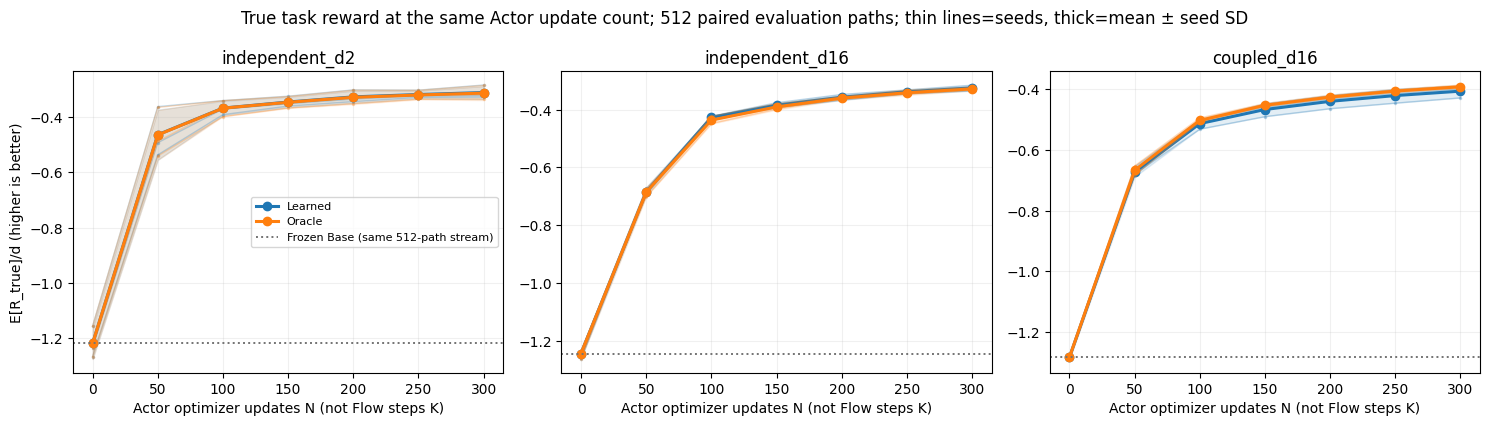

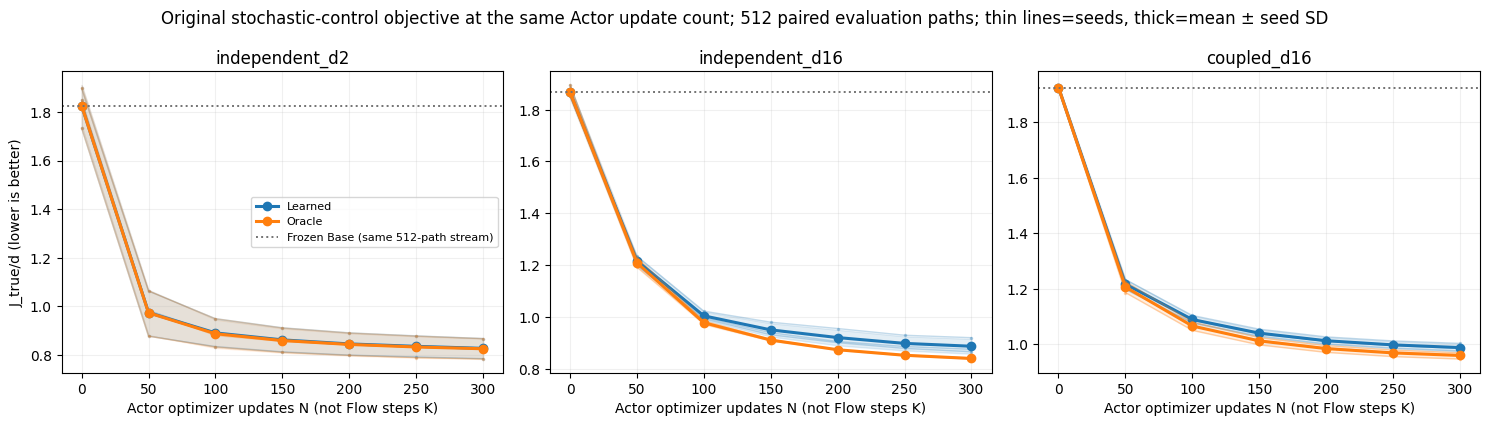

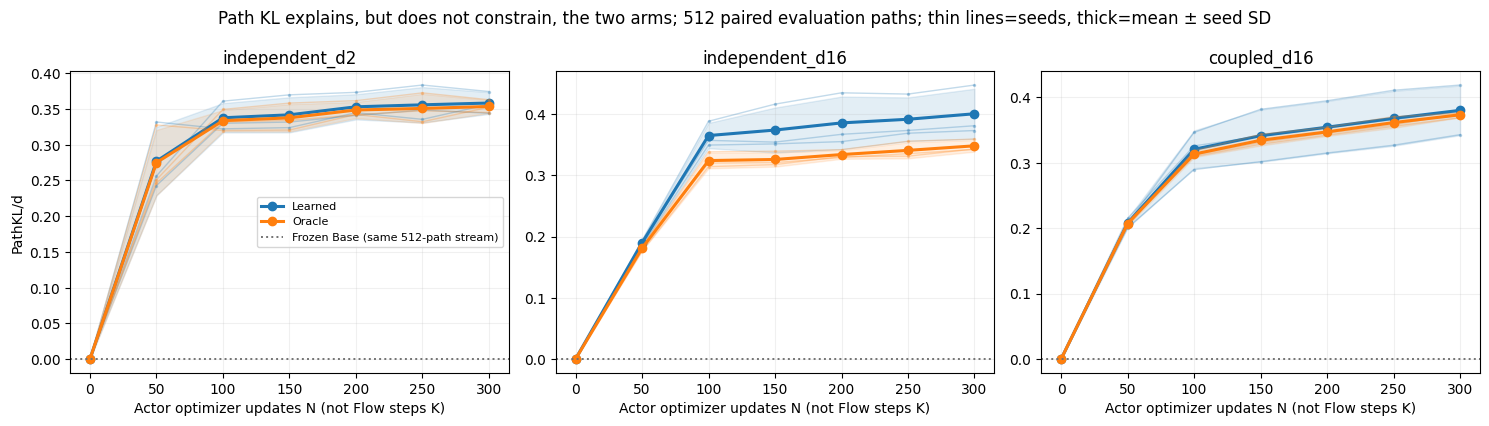

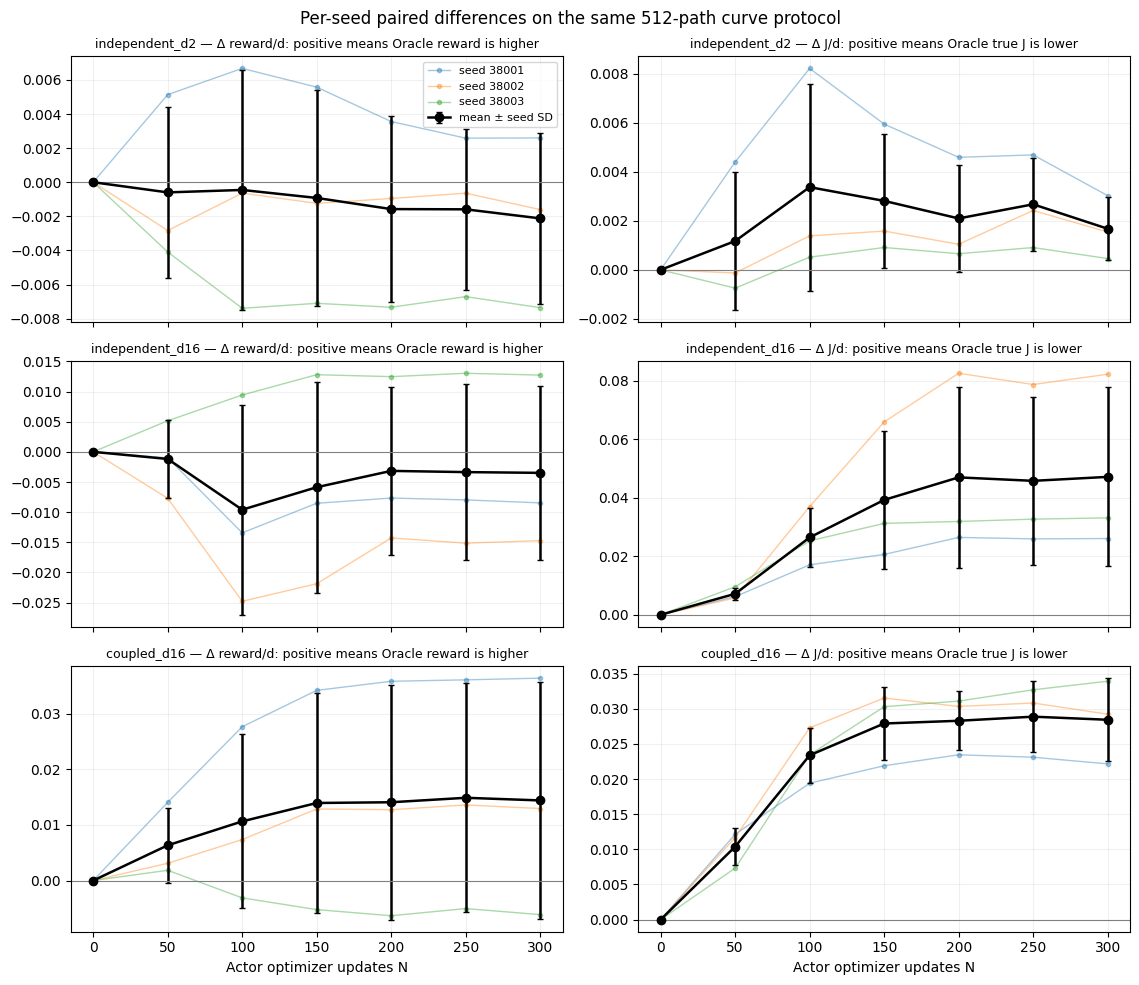

,task,N,delta_reward_mean,delta_reward_seed_sd,reward_positive_seeds,delta_J_mean,delta_J_seed_sd,J_positive_seeds,delta_KL_mean
1,independent_d2,50,-0.000596,0.005004,1,0.001172,0.002806,1,-0.002066
3,independent_d2,150,-0.000921,0.006343,1,0.002810,0.002731,3,-0.004191
6,independent_d2,300,-0.002120,0.004996,1,0.001675,0.001287,3,-0.004855
8,independent_d16,50,-0.001180,0.006432,1,0.007168,0.002087,3,-0.008937
10,independent_d16,150,-0.005865,0.017484,1,0.039239,0.023670,3,-0.048037
13,independent_d16,300,-0.003483,0.014383,1,0.047112,0.030575,3,-0.052337
15,coupled_d16,50,0.006338,0.006718,3,0.010380,0.002657,3,-0.000873
17,coupled_d16,150,0.013950,0.019738,2,0.027893,0.005241,3,-0.006969
20,coupled_d16,300,0.014411,0.021301,2,0.028424,0.005919,3,-0.006808


,task,seed,learned_reward_per_dim,oracle_reward_per_dim,learned_J_per_dim,oracle_J_per_dim,delta_reward_per_dim,delta_J_per_dim,delta_KL_per_dim,final_J_reduction_percent
0,independent_d2,38001,-0.310733,-0.307324,0.802701,0.798265,0.003408,0.004436,0.000676,0.552666
1,independent_d2,38002,-0.300934,-0.302780,0.824172,0.822637,-0.001846,0.001535,-0.004304,0.186225
2,independent_d2,38003,-0.308525,-0.315427,0.831080,0.830318,-0.006901,0.000763,-0.011115,0.091762
3,independent_d16,38001,-0.322585,-0.331104,0.865962,0.839446,-0.008519,0.026516,-0.039294,3.061991
4,independent_d16,38002,-0.318482,-0.332068,0.927005,0.842774,-0.013586,0.084231,-0.104610,9.086324
5,independent_d16,38003,-0.347558,-0.335889,0.899018,0.867726,0.011669,0.031292,-0.013789,3.480722
6,coupled_d16,38001,-0.431922,-0.395640,0.993370,0.971532,0.036282,0.021838,0.032585,2.198351
7,coupled_d16,38002,-0.405165,-0.391598,0.990432,0.961307,0.013567,0.029125,-0.008774,2.940608
8,coupled_d16,38003,-0.398312,-0.404147,1.018353,0.985099,-0.005835,0.033253,-0.042006,3.265386


In [5]:
def paired_updates(curves, c):
    fixed = tuple(range(0, c.actor_updates+1, c.curve_every))
    expected = len(c.tasks)*len(c.seeds)*2*len(fixed)
    if len(curves) != expected or curves.duplicated(['task', 'seed', 'source', 'update']).any():
        raise AssertionError('Missing, duplicated, or extra learning-curve rows')
    rows = []
    for task in c.tasks:
        for seed in c.seeds:
            for method in ('learned', 'oracle'):
                observed = curves[(curves.task == task.name) & (curves.seed == seed)
                                  & (curves.source == method)].sort_values('update')
                if tuple(observed['update']) != fixed:
                    raise AssertionError('Mismatched Actor-update checkpoints')
                residual = observed.cost_per_dim-(observed.energy_per_dim-c.beta*observed.reward_per_dim)
                if float(residual.abs().max()) > 1e-8:
                    raise AssertionError('Curve J does not include the original KL and reward')
            for update in fixed:
                pair = curves[(curves.task == task.name) & (curves.seed == seed)
                              & (curves['update'] == update)].set_index('source')
                learned, oracle = pair.loc['learned'], pair.loc['oracle']
                delta_r = float(oracle.reward_per_dim-learned.reward_per_dim)
                delta_j = float(learned.cost_per_dim-oracle.cost_per_dim)
                delta_kl = float(oracle.energy_per_dim-learned.energy_per_dim)
                if abs(delta_j-(c.beta*delta_r-delta_kl)) > 1e-7:
                    raise AssertionError('Paired curve ΔJ decomposition failed')
                if update == 0 and max(abs(delta_r), abs(delta_j), abs(delta_kl)) > 1e-12:
                    raise AssertionError('Shared Base initialization differs at N=0')
                rows.append(dict(task=task.name, seed=seed, dim=task.dim, N=update,
                                 K=c.steps, B=c.actor_batch, evaluation_paths=c.curve_paths,
                                 evaluation_noise_role=300000,
                                 delta_reward_per_dim=delta_r,
                                 delta_J_per_dim=delta_j,
                                 delta_KL_per_dim=delta_kl))
    paired = pd.DataFrame(rows)
    summary = paired.groupby(['task', 'N'], sort=False).agg(
        delta_reward_mean=('delta_reward_per_dim', 'mean'),
        delta_reward_seed_sd=('delta_reward_per_dim', 'std'),
        reward_positive_seeds=('delta_reward_per_dim', lambda x: int((x > 0).sum())),
        delta_J_mean=('delta_J_per_dim', 'mean'),
        delta_J_seed_sd=('delta_J_per_dim', 'std'),
        J_positive_seeds=('delta_J_per_dim', lambda x: int((x > 0).sum())),
        delta_KL_mean=('delta_KL_per_dim', 'mean'),
        delta_KL_seed_sd=('delta_KL_per_dim', 'std'),
        KL_positive_seeds=('delta_KL_per_dim', lambda x: int((x > 0).sum()))
    ).reset_index()
    summary.insert(2, 'training_seeds', len(c.seeds))
    summary.insert(3, 'evaluation_paths', c.curve_paths)
    return paired, summary


def paired_final(final, c):
    rows = []
    for task in c.tasks:
        for seed in c.seeds:
            frame = final[(final.task == task.name) & (final.seed == seed)].set_index('method')
            if set(frame.index) != {'Frozen Base', 'learned', 'oracle'}:
                raise AssertionError('Incomplete Frozen/Learned/Oracle final evaluation')
            learned, oracle = frame.loc['learned'], frame.loc['oracle']
            delta_r = float(oracle.reward_per_dim-learned.reward_per_dim)
            delta_j = float(learned.cost_per_dim-oracle.cost_per_dim)
            delta_kl = float(oracle.energy_per_dim-learned.energy_per_dim)
            if abs(delta_j-(c.beta*delta_r-delta_kl)) > 1e-7:
                raise AssertionError('Paired final ΔJ decomposition failed')
            rows.append(dict(task=task.name, seed=seed, dim=task.dim, N=c.actor_updates,
                             K=c.steps, B=c.actor_batch, evaluation_paths=c.final_paths,
                             evaluation_noise_role=700000,
                             frozen_reward_per_dim=float(frame.loc['Frozen Base'].reward_per_dim),
                             frozen_J_per_dim=float(frame.loc['Frozen Base'].cost_per_dim),
                             learned_reward_per_dim=float(learned.reward_per_dim),
                             learned_J_per_dim=float(learned.cost_per_dim),
                             oracle_reward_per_dim=float(oracle.reward_per_dim),
                             oracle_J_per_dim=float(oracle.cost_per_dim),
                             learned_KL_per_dim=float(learned.energy_per_dim),
                             oracle_KL_per_dim=float(oracle.energy_per_dim),
                             delta_reward_per_dim=delta_r, delta_J_per_dim=delta_j,
                             delta_KL_per_dim=delta_kl,
                             final_J_reduction_percent=100*delta_j/float(learned.cost_per_dim)))
    return pd.DataFrame(rows)


def plot_update_metric(curves, c, out, metric, title, ylabel, filename):
    fig, axes = plt.subplots(1, len(c.tasks), figsize=(15, 4.3), sharex=True)
    colors = {'learned': 'tab:blue', 'oracle': 'tab:orange'}
    for ax, task in zip(axes, c.tasks):
        subset = curves[curves.task.eq(task.name)]
        for method in ('learned', 'oracle'):
            arm = subset[subset.source.eq(method)]
            for seed in c.seeds:
                row = arm[arm.seed.eq(seed)].sort_values('update')
                ax.plot(row['update'], row[metric], color=colors[method], alpha=.27,
                        lw=1, marker='.', markersize=3)
            grouped = arm.groupby('update')[metric].agg(['mean', 'std'])
            updates = grouped.index.to_numpy(dtype=float)
            center = grouped['mean'].to_numpy(dtype=float)
            spread = grouped['std'].fillna(0).to_numpy(dtype=float)
            ax.plot(updates, center, color=colors[method], marker='o', lw=2.2,
                    label=method.capitalize())
            ax.fill_between(updates, center-spread, center+spread,
                            color=colors[method], alpha=.12)
        frozen = float(subset[subset['update'].eq(0) & subset.source.eq('learned')][metric].mean())
        ax.axhline(frozen, color='.45', ls=':', lw=1.4,
                   label='Frozen Base (same 512-path stream)')
        ax.set_title(task.name)
        ax.set_xlabel('Actor optimizer updates N (not Flow steps K)')
        ax.set_xticks(range(0, c.actor_updates+1, c.curve_every))
        ax.grid(alpha=.18)
    axes[0].set_ylabel(ylabel)
    axes[0].legend(fontsize=8)
    fig.suptitle(title+'; 512 paired evaluation paths; thin lines=seeds, thick=mean ± seed SD')
    fig.tight_layout()
    fig.savefig(out/filename, dpi=155, bbox_inches='tight')
    display(fig); plt.close(fig)
    return filename


def plot_paired_updates(paired, summary, c, out):
    fig, axes = plt.subplots(len(c.tasks), 2, figsize=(11.5, 10), sharex=True)
    quantities = [('delta_reward_per_dim', 'delta_reward_mean', 'delta_reward_seed_sd',
                   'Δ reward/d: positive means Oracle reward is higher'),
                  ('delta_J_per_dim', 'delta_J_mean', 'delta_J_seed_sd',
                   'Δ J/d: positive means Oracle true J is lower')]
    for row_index, task in enumerate(c.tasks):
        by_seed = paired[paired.task.eq(task.name)]
        by_task = summary[summary.task.eq(task.name)].sort_values('N')
        for column, (value, mean, sd, title) in enumerate(quantities):
            ax = axes[row_index, column]
            for seed in c.seeds:
                selected = by_seed[by_seed.seed.eq(seed)].sort_values('N')
                ax.plot(selected['N'], selected[value], marker='.', lw=1, alpha=.4,
                        label=f'seed {seed}' if row_index == 0 and column == 0 else None)
            ax.errorbar(by_task['N'], by_task[mean], yerr=by_task[sd].fillna(0),
                        color='black', marker='o', lw=1.8, capsize=2,
                        label='mean ± seed SD' if row_index == 0 and column == 0 else None)
            ax.axhline(0, color='.5', lw=.8)
            ax.set_title(task.name+' — '+title, fontsize=9)
            ax.set_xticks(range(0, c.actor_updates+1, c.curve_every))
            ax.grid(alpha=.18)
    axes[-1, 0].set_xlabel('Actor optimizer updates N')
    axes[-1, 1].set_xlabel('Actor optimizer updates N')
    axes[0, 0].legend(fontsize=8)
    fig.suptitle('Per-seed paired differences on the same 512-path curve protocol')
    fig.tight_layout()
    filename = 'paired-fixed-update-differences.png'
    fig.savefig(out/filename, dpi=155, bbox_inches='tight')
    display(fig); plt.close(fig)
    return filename


def analyze_fixed_updates(result, c, out):
    paired, summary = paired_updates(result['curves'], c)
    final = paired_final(result['final'], c)
    core_steps = FIXED_SPEC['core_checkpoints'] if FIXED_SPEC else (50, 150, 300)
    core = summary[summary.N.isin(core_steps)].copy()
    paired.to_csv(out/'paired-updates-by-seed.csv', index=False)
    summary.to_csv(out/'paired-updates-summary.csv', index=False)
    core.to_csv(out/'core-checkpoints-50-150-300.csv', index=False)
    final.to_csv(out/'final-4096-paired.csv', index=False)
    save_json(out/'evaluation-protocol.json', dict(
        fixed_update_analysis_spec_sha256=FIXED_SPEC_SHA,
        N_definition='cumulative Actor optimizer.step() calls',
        fixed_N=list(range(0, c.actor_updates+1, c.curve_every)),
        paired_K=c.steps, paired_B=c.actor_batch, beta=c.beta,
        curve=dict(paths=c.curve_paths, role=300000, checkpoints='measured during original training',
                   model_checkpoints_saved=list(c.actor_checkpoints)),
        final=dict(paths=c.final_paths, role=700000, checkpoint=c.actor_updates,
                   source='independent, larger evaluation stream from original final.csv'),
        KL_matched=False, best_checkpoint_selected=False,
        new_checkpoint_evaluations=0, new_actor_optimizer_steps=0 if SOURCE_RUN else 2*len(c.tasks)*len(c.seeds)*c.actor_updates))
    files = [plot_update_metric(result['curves'], c, out, 'reward_per_dim',
                'True task reward at the same Actor update count', 'E[R_true]/d (higher is better)',
                'fixed-updates-true-reward.png'),
             plot_update_metric(result['curves'], c, out, 'cost_per_dim',
                'Original stochastic-control objective at the same Actor update count',
                'J_true/d (lower is better)', 'fixed-updates-true-J.png'),
             plot_update_metric(result['curves'], c, out, 'energy_per_dim',
                'Path KL explains, but does not constrain, the two arms',
                'PathKL/d', 'fixed-updates-path-KL.png'),
             plot_paired_updates(paired, summary, c, out)]
    display(core[['task', 'N', 'delta_reward_mean', 'delta_reward_seed_sd',
                  'reward_positive_seeds', 'delta_J_mean', 'delta_J_seed_sd',
                  'J_positive_seeds', 'delta_KL_mean']])
    display(final[['task', 'seed', 'learned_reward_per_dim', 'oracle_reward_per_dim',
                   'learned_J_per_dim', 'oracle_J_per_dim', 'delta_reward_per_dim',
                   'delta_J_per_dim', 'delta_KL_per_dim', 'final_J_reduction_percent']])
    return dict(paired=paired, summary=summary, core=core, final=final, figures=files)


UPDATE_ANALYSIS = analyze_fixed_updates(RESULTS, CFG, OUT)

## 5. Fixed final checkpoint and compact mechanism measurements

The comparison unit is a training seed, not thousands of evaluation
actions or eight diagnostic repeats. G=(J_learned-J_oracle)/d is
positive if Oracle improves the same regularized true objective.
We show total and per-dimension J, reward, and energy. Across-task
differences are exploratory: changing behavior dependence also
changes the reward model input distribution.

The diagnostic repeats use common actor paths within each repeat.
They measure learned/oracle terminal gradients, propagated adjoints,
matching parameter gradients, and actual Adam one-step differences.
They do not create extra training seeds or alter the formal actors.
Base Jacobian off-diagonal fractions and propagation singular values
are measured without assuming amplification.

In [6]:
def make_figures(result, c, out):
    files = []
    fig, axes = plt.subplots(3, 2, figsize=(12, 13))
    for row, task in enumerate(c.tasks):
        samples = result['visual'][task.name]
        for column, pair in enumerate(((0, 1), (task.dim//2-1, task.dim//2))):
            ax = axes[row, column]
            for name, color in [('behavior', 'black'), ('ode', 'tab:blue'), ('sde', 'tab:orange')]:
                values = samples[name][:768].numpy()
                ax.scatter(values[:, pair[0]], values[:, pair[1]], s=3, alpha=.23,
                           color=color, label=name)
            ax.set_title(f'{task.name}: coordinates {pair[0]+1},{pair[1]+1}')
            ax.set_xlabel(f'a_{pair[0]+1}')
            ax.set_ylabel(f'a_{pair[1]+1}')
            ax.grid(alpha=.15)
    axes[0, 0].legend(markerscale=3)
    fig.suptitle('Behavior and learned Base samples: 2D projections only')
    fig.tight_layout()
    fig.savefig(out/'behavior-base-projections.png', dpi=155, bbox_inches='tight')
    display(fig); plt.close(fig)
    files.append('behavior-base-projections.png')

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    metrics = [('cost_per_dim', 'True J/d (lower better)'),
               ('reward_per_dim', 'True reward/d'),
               ('energy_per_dim', 'Path KL/d')]
    colors = {'Frozen Base': '0.5', 'learned': 'tab:blue', 'oracle': 'tab:orange'}
    for ax, (metric, title) in zip(axes, metrics):
        for offset, method in enumerate(('Frozen Base', 'learned', 'oracle')):
            subset = result['final'][result['final'].method.eq(method)]
            grouped = subset.groupby('task')[metric].agg(['mean', 'std'])
            names = [task.name for task in c.tasks]
            positions = np.arange(len(names))+(offset-1)*.25
            ax.bar(positions, grouped.loc[names, 'mean'], width=.24,
                   yerr=grouped.loc[names, 'std'], color=colors[method],
                   label=method, capsize=3)
        ax.set_xticks(range(3), [task.name.replace('_', '\n') for task in c.tasks])
        ax.set_title(title)
        ax.grid(axis='y', alpha=.2)
    axes[0].legend(fontsize=8)
    fig.suptitle('Fixed 300-update checkpoint; bars = seed mean, whiskers = seed SD')
    fig.tight_layout()
    fig.savefig(out/'final-reward-KL-J.png', dpi=155, bbox_inches='tight')
    display(fig); plt.close(fig)
    files.append('final-reward-KL-J.png')

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
    task_names = [task.name for task in c.tasks]
    diagnostics = result['diagnostics'][result['diagnostics'].checkpoint_step.eq(c.actor_updates)]
    for ax, column, title in zip(
            axes, ('terminal_gradient_relative_rms', 'q_relative_difference',
                   'step_relative_difference'),
            ('Terminal gradient relative RMS', 'Matching gradient relative difference',
             'Shared-history Adam step relative difference')):
        grouped = diagnostics.groupby('task')[column].agg(['mean', 'std'])
        ax.bar(range(3), grouped.loc[task_names, 'mean'],
               yerr=grouped.loc[task_names, 'std'], capsize=3, color='tab:purple')
        ax.set_xticks(range(3), [name.replace('_', '\n') for name in task_names])
        ax.set_title(title)
        ax.grid(axis='y', alpha=.2)
    fig.suptitle('Fixed learned final checkpoint; whiskers describe probe variation')
    fig.tight_layout()
    fig.savefig(out/'terminal-gradient-to-Adam.png', dpi=155, bbox_inches='tight')
    display(fig); plt.close(fig)
    files.append('terminal-gradient-to-Adam.png')

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
    for index, task in enumerate(c.tasks):
        sample = result['gains'][result['gains'].task.eq(task.name)]
        axes[0].scatter(np.full(len(sample), index)+np.linspace(-.06, .06, len(sample)),
                        sample.oracle_gain_J_per_dim, label=task.name)
        axes[0].plot(index, sample.oracle_gain_J_per_dim.mean(), 'kD')
    axes[0].axhline(0, color='black', lw=.8)
    axes[0].set_xticks(range(3), [name.replace('_', '\n') for name in task_names])
    axes[0].set_title('Oracle gain G=(J_L-J_O)/d')
    axes[0].set_ylabel('Positive favors Oracle')
    structure = result['structure'][result['structure'].checkpoint_step.eq(0)]
    grouped = structure.groupby('task')[['base_jacobian_offdiag_fraction',
                                          'propagator_sigma_max']].mean()
    axes[1].plot(range(3), grouped.loc[task_names, 'base_jacobian_offdiag_fraction'],
                 'o-', label='Base Jacobian off-diagonal fraction')
    axes[1].plot(range(3), grouped.loc[task_names, 'propagator_sigma_max'],
                 's--', label='Propagation max singular value')
    axes[1].set_xticks(range(3), [name.replace('_', '\n') for name in task_names])
    axes[1].set_title('Measured propagation structure')
    axes[1].legend(fontsize=8)
    for ax in axes:
        ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(out/'oracle-gain-and-propagation.png', dpi=155, bbox_inches='tight')
    display(fig); plt.close(fig)
    files.append('oracle-gain-and-propagation.png')
    return files


def markdown_table(frame, columns):
    selected = frame[columns].copy()
    for column in selected.select_dtypes(include='number').columns:
        selected[column] = selected[column].map(
            lambda x: f'{x:.6g}' if pd.notna(x) else 'NA')
    return '\n'.join([
        '| '+' | '.join(columns)+' |',
        '| '+' | '.join('---' for _ in columns)+' |',
        *['| '+' | '.join(str(item) for item in row)+' |'
          for row in selected.itertuples(index=False, name=None)]
    ])


def make_report(result, c, files):
    summary = result['final'].groupby(['task', 'method'])[
        ['cost', 'cost_per_dim', 'reward_per_dim', 'energy_per_dim']].agg(['mean', 'std'])
    summary.columns = [f'{name}_{stat}' for name, stat in summary.columns]
    summary = summary.reset_index()
    gains = result['gains'].groupby('task')[['oracle_gain_J_per_dim',
                                            'oracle_gain_over_frozen_J']].agg(['mean', 'std'])
    gains.columns = [f'{name}_{stat}' for name, stat in gains.columns]
    gains = gains.reset_index()
    final_diagnostics = result['diagnostics'][
        result['diagnostics'].checkpoint_step.eq(c.actor_updates)]
    mechanism = final_diagnostics.groupby('task')[
        ['value_rmse_over_true_reward_std', 'terminal_gradient_relative_rms',
         'q_relative_difference', 'step_relative_difference']].mean().reset_index()
    structure = result['structure'][result['structure'].checkpoint_step.eq(0)].groupby('task')[
        ['base_jacobian_offdiag_fraction', 'propagator_sigma_max',
         'propagator_sigma_min']].mean().reset_index()
    base = result['quality'].groupby('task')[
        ['base_step0_fm_loss_per_dim', 'base_heldout_fm_loss_per_dim',
         'ode_random_projection_w2', 'sde_random_projection_w2',
         'ode_adjacent_corr_gap_rms', 'sde_adjacent_corr_gap_rms']].mean().reset_index()
    gap = gains.set_index('task')['oracle_gain_J_per_dim_mean']
    gradient = mechanism.set_index('task')['terminal_gradient_relative_rms']
    g_a, g_b, g_c = (float(gap[task.name]) for task in c.tasks)
    e_a, e_b, e_c = (float(gradient[task.name]) for task in c.tasks)
    lines = [
        '# Terminal-gradient dimension × generative coupling: executed exploratory run',
        '',
        f'Fixed tasks: {[task.name for task in c.tasks]}; seeds {list(c.seeds)}. '
        f'Each task-seed uses {c.behavior_train} behavior training actions, '
        f'{c.reward_train} noisy scalar reward labels, {c.ensemble_members} reward models, '
        f'{c.fm_updates} FM updates and {c.actor_updates} updates per actor. '
        'The three seed numbers are new to this repository but this is exploratory.',
        '',
        '## Direct answer', '',
        f'Final learned-checkpoint terminal-gradient relative RMS means: '
        f'A={e_a:.4g}, B={e_b:.4g}, C={e_c:.4g}. '
        f'Oracle gain G=(J_learned-J_oracle)/d means: '
        f'A={g_a:.5g}, B={g_b:.5g}, C={g_c:.5g}. '
        'Positive G favors Oracle on the same true reward-versus-KL objective.',
        '',
        ('Dimension increase coincides with a larger measured terminal-gradient error in '
         'this run.' if e_b > e_a else
         'Dimension increase does not coincide with a larger measured terminal-gradient error in this run.'),
        ('The coupled setting has a larger measured Base Jacobian off-diagonal fraction '
         'than independent d16.' if float(structure.set_index('task').loc[c.tasks[2].name,
         'base_jacobian_offdiag_fraction']) >
         float(structure.set_index('task').loc[c.tasks[1].name,
         'base_jacobian_offdiag_fraction']) else
         'The coupled setting does not have a larger measured Base Jacobian off-diagonal fraction '
         'than independent d16.'),
        ('The d16 independent Oracle gain exceeds d2 in this run.' if g_b > g_a
         else 'The d16 independent Oracle gain does not exceed d2 in this run.'),
        ('The d16 coupled Oracle gain exceeds d16 independent in this run.' if g_c > g_b
         else 'The d16 coupled Oracle gain does not exceed d16 independent in this run.'),
        'These comparisons do not isolate adjoint propagation from reward-model fit, '
        'state distribution, or pretrained Base quality. Three training seeds support '
        'an initial diagnosis, not a general dimension law.',
        '',
        '## Every final seed and method', '',
        markdown_table(result['final'], ['task', 'seed', 'method', 'cost', 'cost_per_dim',
                                          'reward_per_dim', 'energy_per_dim',
                                          'kl_identity_max_abs']), '',
        '## Task means and training-seed SD', '',
        markdown_table(summary, ['task', 'method', 'cost_mean', 'cost_std',
                                 'cost_per_dim_mean', 'cost_per_dim_std',
                                 'reward_per_dim_mean', 'reward_per_dim_std',
                                 'energy_per_dim_mean', 'energy_per_dim_std']), '',
        '## Per-seed Oracle gains and Oracle versus Frozen', '',
        markdown_table(result['gains'], ['task', 'seed', 'oracle_gain_J',
                                         'oracle_gain_J_per_dim',
                                         'oracle_gain_over_frozen_J']), '',
        'Task mean and seed SD of the gains:', '',
        markdown_table(gains, ['task', 'oracle_gain_J_per_dim_mean',
                               'oracle_gain_J_per_dim_std',
                               'oracle_gain_over_frozen_J_mean',
                               'oracle_gain_over_frozen_J_std']), '',
        'An Oracle reward increase alone is insufficient: the cost column includes '
        'the exact finite-chain KL energy. If Oracle cannot improve Frozen on a task, '
        'Base quality or finite optimization limits are immediate constraints.',
        '',
        '## Reward fit and propagation mechanism', '',
        markdown_table(mechanism, ['task', 'value_rmse_over_true_reward_std',
                                   'terminal_gradient_relative_rms',
                                   'q_relative_difference',
                                   'step_relative_difference']), '',
        'The full diagnostics CSV also contains gradient cosines/norm ratios, zero-scale '
        f'flags, raw value RMSE, and {c.diagnostic_repeats} separate rollout repeats at the initial and '
        'learned-final checkpoints. The adjoint-time CSV reports both absolute error '
        'and correct signal RMS at four fixed times. The shared-history virtual Adam '
        'step does not predict the entire independent training trajectory.', '',
        markdown_table(structure, ['task', 'base_jacobian_offdiag_fraction',
                                   'propagator_sigma_max',
                                   'propagator_sigma_min']), '',
        'A singular value below one means contraction for that measured direction; '
        'no amplification threshold was imposed.',
        '',
        '## Pretrained Base quality', '',
        markdown_table(base, ['task', 'base_step0_fm_loss_per_dim',
                              'base_heldout_fm_loss_per_dim',
                              'ode_random_projection_w2',
                              'sde_random_projection_w2',
                              'ode_adjacent_corr_gap_rms',
                              'sde_adjacent_corr_gap_rms']), '',
        'Each seed has per-coordinate mean/variance and adjacent-correlation arrays, '
        'paired behavior/Base ODE/Base SDE samples, and inverse-transform Gaussian '
        'checks. Random-projection W2 and 2D plots are partial fit diagnostics, '
        'not full high-dimensional distribution metrics.',
        '',
        '## Fixed training and measurement budgets', '',
        markdown_table(result['budgets'], ['task', 'seed', 'source', 'updates',
                                            'training_rollouts', 'stochastic_velocity_calls',
                                            'warmup_velocity_calls', 'oracle_gradient_points',
                                            'clipping_count', 'wall_seconds']), '',
        'FM loss and matching loss are divided by d. Reward and energy are both left '
        'in the same true objective J; division by d in summaries does not alter beta. '
        'The observed-data noise scale was calibrated on an independent fixed behavior '
        'sample for each task-seed before reward fitting. Learned actor updates were '
        'run with the truth API blocked.',
        '',
        '## Limits and next question', '',
        'This first round changes both reward-model input distribution and the learned '
        'Flow when rho changes. It cannot assign a larger B/C gap uniquely to the '
        'adjoint. An optional oracle-assisted equal-error diagnostic is specified in '
        'the config but disabled; no kappa intervention was run. '
        'The previous four-mode 2D negative result is retained separately.',
        '',
        'Figures: '+', '.join(files)+'. All data and checkpoints reside in this unique run.'
    ]
    return '\n'.join(lines)+'\n'


def make_fixed_update_report(result, analysis, c, source):
    core = analysis['core']
    final = analysis['final']
    final_means = final.groupby('task').agg(
        delta_reward_mean=('delta_reward_per_dim', 'mean'),
        delta_reward_seed_sd=('delta_reward_per_dim', 'std'),
        reward_positive_seeds=('delta_reward_per_dim', lambda x: int((x > 0).sum())),
        delta_J_mean=('delta_J_per_dim', 'mean'),
        delta_J_seed_sd=('delta_J_per_dim', 'std'),
        J_positive_seeds=('delta_J_per_dim', lambda x: int((x > 0).sum())),
        delta_KL_mean=('delta_KL_per_dim', 'mean')).reset_index()
    mechanism = result['diagnostics'][result['diagnostics'].checkpoint_step.eq(c.actor_updates)]
    mechanism = mechanism.groupby('task')[
        ['terminal_gradient_relative_rms', 'q_relative_difference',
         'step_relative_difference']].mean().reset_index()
    key_columns = ['task', 'N', 'delta_reward_mean', 'delta_reward_seed_sd',
                   'reward_positive_seeds', 'delta_J_mean', 'delta_J_seed_sd',
                   'J_positive_seeds', 'delta_KL_mean']
    stage_text = []
    for task in c.tasks:
        rows = core[core.task.eq(task.name)].set_index('N')
        bits = []
        for step in (50, 150, 300):
            row = rows.loc[step]
            bits.append(f'N={step}: reward {int(row.reward_positive_seeds)}/3, '
                        f'J {int(row.J_positive_seeds)}/3 seeds favor Oracle')
        stage_text.append(f'- {task.name}: '+ '; '.join(bits)+'.')
    by_task = {task.name: core[core.task.eq(task.name)].set_index('N') for task in c.tasks}
    d2 = by_task['independent_d2']
    d16 = by_task['independent_d16']
    coupled = by_task['coupled_d16']
    final_columns = ['task', 'seed', 'learned_reward_per_dim', 'oracle_reward_per_dim',
                     'learned_J_per_dim', 'oracle_J_per_dim',
                     'learned_KL_per_dim', 'oracle_KL_per_dim',
                     'delta_reward_per_dim', 'delta_J_per_dim',
                     'delta_KL_per_dim', 'final_J_reduction_percent']
    lines = [
        '# Same Actor-update budget: terminal-gradient reliability in Lean AM', '',
        'Primary question: after the same number N of Actor optimizer.step() calls, '
        'does Oracle terminal-gradient access yield higher true task reward, lower '
        'true stochastic-control J, or both? Oracle is a truth-assisted diagnostic, '
        'not a deployable algorithm or theoretical upper bound.', '',
        '## Provenance and what was executed', '',
        f'This is a read-only reanalysis of `{source.relative_to(ROOT)}`. '
        'The original three tasks × three seeds × two Actor arms had already '
        'completed 300 updates each. No Actor, Base or reward model was retrained; '
        'zero new optimizer steps and zero new checkpoint evaluations were performed. '
        'The models and data remain in the source run. The new output directory '
        'contains analyses, figures, the source manifest and this report.', '',
        f'N is Actor parameter updates; K={c.steps} is Flow EM discretization, '
        f'B={c.actor_batch} is rollout paths per update. Both arms share N/K/B, '
        'Base, scalar data, reward ensemble, initial Actor, initial Adam state '
        'and pairable training/evaluation noise. Their state paths differ after '
        'policies diverge. The intervention is only the terminal label source. '
        'Lean AM, not full adjoint or BPTT, is used in both arms.', '',
        f'The complete learning curve uses N={list(range(0, c.actor_updates+1, c.curve_every))} '
        f'and {c.curve_paths} common evaluation paths per task-seed (noise role 300000). '
        'It was measured during original training. Only N=0,150,300 model/optimizer '
        'checkpoints were serialized; N=50,100,200,250 are real curve measurements, '
        'not reconstructed models. The independent N=300 final table uses '
        f'{c.final_paths} different paths (noise role 700000); it is never spliced '
        'into the 512-path curve.', '',
        '## Reward versus Actor updates (higher is better)', '',
        'Each task has unsmoothed Learned/Oracle curves with every seed, their mean '
        'and training-seed SD, and a Frozen Base N=0 reference. See '
        '`fixed-updates-true-reward.png` and the exact 126 source curve rows.', '',
        '## True SOC J versus Actor updates (lower is better)', '',
        'The original objective remains `J=PathKL-beta E[R_true]`, beta=1.5. '
        'No post-hoc PathKL matching, actor scaling, checkpoint selection or '
        'extra energy loss was performed. See `fixed-updates-true-J.png`.', '',
        '## Paired checkpoint effects', '',
        'Define `Delta_R=(R_Oracle-R_Learned)/d`, '
        '`Delta_J=(J_Learned-J_Oracle)/d`, '
        '`Delta_KL=(KL_Oracle-KL_Learned)/d`. '
        'Positive Delta_R means higher Oracle task reward; positive Delta_J '
        'means lower Oracle true J. Every row obeys '
        '`Delta_J=beta*Delta_R-Delta_KL`. Pair within seed first, then aggregate. '
        'The table below is the pre-specified N=50/150/300 summary; '
        '`paired-updates-by-seed.csv` and `paired-updates-summary.csv` keep all '
        'three seeds and all seven update points.', '',
        markdown_table(core, key_columns), '',
        'Direction counts at the three highlighted checkpoints:', '',
        *stage_text, '',
        'Direct fixed-N reading of this run:', '',
        f'- independent_d2: mean Delta_J/d is {d2.loc[50, "delta_J_mean"]:.5g} '
        f'at N=50 and {d2.loc[300, "delta_J_mean"]:.5g} at N=300; '
        f'the N=300 mean reward difference is {d2.loc[300, "delta_reward_mean"]:.5g}. '
        'A small J advantage does not imply a reward advantage.',
        f'- independent_d16: mean Delta_J/d rises from '
        f'{d16.loc[50, "delta_J_mean"]:.5g} at N=50 to '
        f'{d16.loc[300, "delta_J_mean"]:.5g} at N=300, while '
        f'the mean N=300 Delta_R/d is {d16.loc[300, "delta_reward_mean"]:.5g} '
        f'and Delta_KL/d is {d16.loc[300, "delta_KL_mean"]:.5g}. '
        'This is earlier and accumulating J separation, not evidence of '
        'consistently higher reward or a measured training-speed ratio.',
        f'- coupled_d16: mean Delta_R/d and Delta_J/d are '
        f'{coupled.loc[50, "delta_reward_mean"]:.5g} and '
        f'{coupled.loc[50, "delta_J_mean"]:.5g} at N=50, versus '
        f'{coupled.loc[300, "delta_reward_mean"]:.5g} and '
        f'{coupled.loc[300, "delta_J_mean"]:.5g} at N=300; '
        f'final curve directions are {int(coupled.loc[300, "reward_positive_seeds"])}/3 '
        f'for reward and {int(coupled.loc[300, "J_positive_seeds"])}/3 for J.', '',
        '## Path KL as explanation, not a matching condition', '',
        'See `fixed-updates-path-KL.png` and `delta_KL_mean` above. '
        'A lower J does not imply higher reward; a higher reward does not imply '
        'lower J. Differences in control intensity are allowed and explicitly '
        'accounted for by the original J.', '',
        '## Independent high-sample N=300 final table', '',
        markdown_table(final, final_columns), '',
        'The final J reduction percentage is `(J_Learned-J_Oracle)/J_Learned×100` '
        'for this fixed checkpoint only. It is not an update-count saving or '
        'wall-clock acceleration. Final paired means, seed SD and direction counts:', '',
        markdown_table(final_means, ['task', 'delta_reward_mean',
             'delta_reward_seed_sd', 'reward_positive_seeds', 'delta_J_mean',
             'delta_J_seed_sd', 'J_positive_seeds', 'delta_KL_mean']), '',
        '## Compact mechanism readout', '',
        markdown_table(mechanism, ['task', 'terminal_gradient_relative_rms',
                                   'q_relative_difference',
                                   'step_relative_difference']), '',
        'These existing common-path/shared-Adam-history diagnostics describe '
        'label, local matching-gradient and one-step optimizer discrepancies. '
        'They do not establish the true J policy gradient or equate the two '
        'independent training histories. A more accurate terminal gradient '
        'need not improve every reward checkpoint.', '',
        '## Scope of the conclusion', '',
        'The tables answer fixed-N performance separately for true reward and '
        'true J, including stages where their directions differ. Three explored '
        'training seeds and 300 steps do not establish a general convergence '
        'rate, asymptotic optimum, or causal isolation of critic error from '
        'Base quality and evolving state distributions. Future robust methods '
        'must use the same data, initial Actor, B, K and actual N optimizer '
        'steps; any extra forward/adjoint/critic computation must be logged '
        'separately. No such new method is implemented here.', '',
        'Figures: '+', '.join(analysis['figures'])+'.'
    ]
    return '\n'.join(lines)+'\n'


if SOURCE_RUN:
    FIGURES = UPDATE_ANALYSIS['figures']
    REPORT = make_fixed_update_report(RESULTS, UPDATE_ANALYSIS, CFG, SOURCE_RUN)
else:
    FIGURES = UPDATE_ANALYSIS['figures']+make_figures(RESULTS, CFG, OUT)
    REPORT = make_report(RESULTS, CFG, FIGURES)
(OUT/'report.md').write_text(REPORT)
save_json(OUT/'completion.json', dict(status='complete', profile=CFG.profile,
          kind='read_only_fixed_update_reanalysis' if SOURCE_RUN else 'fresh_training',
          source_run=str(SOURCE_RUN.relative_to(ROOT)) if SOURCE_RUN else None,
          tasks=[task.name for task in CFG.tasks], seeds=list(CFG.seeds),
          new_base_runs=0 if SOURCE_RUN else len(CFG.tasks)*len(CFG.seeds),
          new_reward_models=0 if SOURCE_RUN else len(CFG.tasks)*len(CFG.seeds)*CFG.ensemble_members,
          new_actor_runs=0 if SOURCE_RUN else 2*len(CFG.tasks)*len(CFG.seeds),
          new_actor_optimizer_steps=0 if SOURCE_RUN else 2*len(CFG.tasks)*len(CFG.seeds)*CFG.actor_updates,
          new_checkpoint_evaluations=0 if SOURCE_RUN else len(CFG.tasks)*len(CFG.seeds)*3,
          figures=FIGURES, elapsed_seconds=time.monotonic()-START,
          formal_spec_sha256=CONFIG_SHA, fixed_update_spec_sha256=FIXED_SPEC_SHA,
          source_sha256=SOURCE_SHA))
record_event(OUT, 'analysis_complete', new_actor_optimizer_steps=0 if SOURCE_RUN else
             2*len(CFG.tasks)*len(CFG.seeds)*CFG.actor_updates)
display(Markdown(REPORT))
print('Complete run:', OUT.relative_to(ROOT))

# Same Actor-update budget: terminal-gradient reliability in Lean AM

Primary question: after the same number N of Actor optimizer.step() calls, does Oracle terminal-gradient access yield higher true task reward, lower true stochastic-control J, or both? Oracle is a truth-assisted diagnostic, not a deployable algorithm or theoretical upper bound.

## Provenance and what was executed

This is a read-only reanalysis of `runs/02-flow-am-dim-formal-8q5obfng`. The original three tasks × three seeds × two Actor arms had already completed 300 updates each. No Actor, Base or reward model was retrained; zero new optimizer steps and zero new checkpoint evaluations were performed. The models and data remain in the source run. The new output directory contains analyses, figures, the source manifest and this report.

N is Actor parameter updates; K=64 is Flow EM discretization, B=64 is rollout paths per update. Both arms share N/K/B, Base, scalar data, reward ensemble, initial Actor, initial Adam state and pairable training/evaluation noise. Their state paths differ after policies diverge. The intervention is only the terminal label source. Lean AM, not full adjoint or BPTT, is used in both arms.

The complete learning curve uses N=[0, 50, 100, 150, 200, 250, 300] and 512 common evaluation paths per task-seed (noise role 300000). It was measured during original training. Only N=0,150,300 model/optimizer checkpoints were serialized; N=50,100,200,250 are real curve measurements, not reconstructed models. The independent N=300 final table uses 4096 different paths (noise role 700000); it is never spliced into the 512-path curve.

## Reward versus Actor updates (higher is better)

Each task has unsmoothed Learned/Oracle curves with every seed, their mean and training-seed SD, and a Frozen Base N=0 reference. See `fixed-updates-true-reward.png` and the exact 126 source curve rows.

## True SOC J versus Actor updates (lower is better)

The original objective remains `J=PathKL-beta E[R_true]`, beta=1.5. No post-hoc PathKL matching, actor scaling, checkpoint selection or extra energy loss was performed. See `fixed-updates-true-J.png`.

## Paired checkpoint effects

Define `Delta_R=(R_Oracle-R_Learned)/d`, `Delta_J=(J_Learned-J_Oracle)/d`, `Delta_KL=(KL_Oracle-KL_Learned)/d`. Positive Delta_R means higher Oracle task reward; positive Delta_J means lower Oracle true J. Every row obeys `Delta_J=beta*Delta_R-Delta_KL`. Pair within seed first, then aggregate. The table below is the pre-specified N=50/150/300 summary; `paired-updates-by-seed.csv` and `paired-updates-summary.csv` keep all three seeds and all seven update points.

| task | N | delta_reward_mean | delta_reward_seed_sd | reward_positive_seeds | delta_J_mean | delta_J_seed_sd | J_positive_seeds | delta_KL_mean |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| independent_d2 | 50 | -0.000595679 | 0.00500424 | 1 | 0.00117249 | 0.00280596 | 1 | -0.00206601 |
| independent_d2 | 150 | -0.000921058 | 0.00634317 | 1 | 0.00280961 | 0.00273091 | 3 | -0.0041912 |
| independent_d2 | 300 | -0.00212015 | 0.00499566 | 1 | 0.00167515 | 0.00128695 | 3 | -0.00485537 |
| independent_d16 | 50 | -0.00117982 | 0.00643199 | 1 | 0.00716772 | 0.00208669 | 3 | -0.00893745 |
| independent_d16 | 150 | -0.00586507 | 0.0174841 | 1 | 0.0392393 | 0.0236701 | 3 | -0.0480369 |
| independent_d16 | 300 | -0.00348329 | 0.0143834 | 1 | 0.0471122 | 0.030575 | 3 | -0.0523372 |
| coupled_d16 | 50 | 0.00633778 | 0.00671833 | 3 | 0.0103798 | 0.00265728 | 3 | -0.000873177 |
| coupled_d16 | 150 | 0.0139497 | 0.0197375 | 2 | 0.0278932 | 0.00524061 | 3 | -0.00696869 |
| coupled_d16 | 300 | 0.0144107 | 0.0213006 | 2 | 0.0284243 | 0.0059186 | 3 | -0.0068082 |

Direction counts at the three highlighted checkpoints:

- independent_d2: N=50: reward 1/3, J 1/3 seeds favor Oracle; N=150: reward 1/3, J 3/3 seeds favor Oracle; N=300: reward 1/3, J 3/3 seeds favor Oracle.
- independent_d16: N=50: reward 1/3, J 3/3 seeds favor Oracle; N=150: reward 1/3, J 3/3 seeds favor Oracle; N=300: reward 1/3, J 3/3 seeds favor Oracle.
- coupled_d16: N=50: reward 3/3, J 3/3 seeds favor Oracle; N=150: reward 2/3, J 3/3 seeds favor Oracle; N=300: reward 2/3, J 3/3 seeds favor Oracle.

Direct fixed-N reading of this run:

- independent_d2: mean Delta_J/d is 0.0011725 at N=50 and 0.0016751 at N=300; the N=300 mean reward difference is -0.0021202. A small J advantage does not imply a reward advantage.
- independent_d16: mean Delta_J/d rises from 0.0071677 at N=50 to 0.047112 at N=300, while the mean N=300 Delta_R/d is -0.0034833 and Delta_KL/d is -0.052337. This is earlier and accumulating J separation, not evidence of consistently higher reward or a measured training-speed ratio.
- coupled_d16: mean Delta_R/d and Delta_J/d are 0.0063378 and 0.01038 at N=50, versus 0.014411 and 0.028424 at N=300; final curve directions are 2/3 for reward and 3/3 for J.

## Path KL as explanation, not a matching condition

See `fixed-updates-path-KL.png` and `delta_KL_mean` above. A lower J does not imply higher reward; a higher reward does not imply lower J. Differences in control intensity are allowed and explicitly accounted for by the original J.

## Independent high-sample N=300 final table

| task | seed | learned_reward_per_dim | oracle_reward_per_dim | learned_J_per_dim | oracle_J_per_dim | learned_KL_per_dim | oracle_KL_per_dim | delta_reward_per_dim | delta_J_per_dim | delta_KL_per_dim | final_J_reduction_percent |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| independent_d2 | 38001 | -0.310733 | -0.307324 | 0.802701 | 0.798265 | 0.336602 | 0.337279 | 0.0034083 | 0.00443626 | 0.000676185 | 0.552666 |
| independent_d2 | 38002 | -0.300934 | -0.30278 | 0.824172 | 0.822637 | 0.37277 | 0.368466 | -0.00184601 | 0.00153481 | -0.00430383 | 0.186225 |
| independent_d2 | 38003 | -0.308525 | -0.315427 | 0.83108 | 0.830318 | 0.368292 | 0.357177 | -0.00690136 | 0.000762617 | -0.0111147 | 0.0917622 |
| independent_d16 | 38001 | -0.322585 | -0.331104 | 0.865962 | 0.839446 | 0.382085 | 0.342791 | -0.00851912 | 0.0265157 | -0.0392944 | 3.06199 |
| independent_d16 | 38002 | -0.318482 | -0.332068 | 0.927005 | 0.842774 | 0.449282 | 0.344672 | -0.0135863 | 0.0842307 | -0.10461 | 9.08632 |
| independent_d16 | 38003 | -0.347558 | -0.335889 | 0.899018 | 0.867726 | 0.377681 | 0.363892 | 0.0116692 | 0.0312923 | -0.0137886 | 3.48072 |
| coupled_d16 | 38001 | -0.431922 | -0.39564 | 0.99337 | 0.971532 | 0.345487 | 0.378072 | 0.0362821 | 0.0218378 | 0.0325854 | 2.19835 |
| coupled_d16 | 38002 | -0.405165 | -0.391598 | 0.990432 | 0.961307 | 0.382685 | 0.373911 | 0.0135672 | 0.0291247 | -0.00877387 | 2.94061 |
| coupled_d16 | 38003 | -0.398312 | -0.404147 | 1.01835 | 0.985099 | 0.420884 | 0.378879 | -0.00583512 | 0.0332531 | -0.0420058 | 3.26539 |

The final J reduction percentage is `(J_Learned-J_Oracle)/J_Learned×100` for this fixed checkpoint only. It is not an update-count saving or wall-clock acceleration. Final paired means, seed SD and direction counts:

| task | delta_reward_mean | delta_reward_seed_sd | reward_positive_seeds | delta_J_mean | delta_J_seed_sd | J_positive_seeds | delta_KL_mean |
| --- | --- | --- | --- | --- | --- | --- | --- |
| coupled_d16 | 0.0146714 | 0.0210803 | 2 | 0.0280719 | 0.00578006 | 3 | -0.00606475 |
| independent_d16 | -0.00347875 | 0.0133609 | 1 | 0.0473462 | 0.032032 | 3 | -0.0525644 |
| independent_d2 | -0.00177969 | 0.00515515 | 1 | 0.00224456 | 0.00193694 | 3 | -0.0049141 |

## Compact mechanism readout

| task | terminal_gradient_relative_rms | q_relative_difference | step_relative_difference |
| --- | --- | --- | --- |
| coupled_d16 | 0.306346 | 0.90783 | 0.580438 |
| independent_d16 | 0.404659 | 0.973097 | 0.655054 |
| independent_d2 | 0.113227 | 0.575841 | 0.324589 |

These existing common-path/shared-Adam-history diagnostics describe label, local matching-gradient and one-step optimizer discrepancies. They do not establish the true J policy gradient or equate the two independent training histories. A more accurate terminal gradient need not improve every reward checkpoint.

## Scope of the conclusion

The tables answer fixed-N performance separately for true reward and true J, including stages where their directions differ. Three explored training seeds and 300 steps do not establish a general convergence rate, asymptotic optimum, or causal isolation of critic error from Base quality and evolving state distributions. Future robust methods must use the same data, initial Actor, B, K and actual N optimizer steps; any extra forward/adjoint/critic computation must be logged separately. No such new method is implemented here.

Figures: fixed-updates-true-reward.png, fixed-updates-true-J.png, fixed-updates-path-KL.png, paired-fixed-update-differences.png.


Complete run: runs/02-flow-am-update-analysis-formal-q6xpxevn
